In [1]:
from pathlib import Path
import sys
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_project_root(start: Path) -> Path:
    current = start.resolve()
    while current != current.parent:
        if (current / "src").exists():
            return current
        current = current.parent
    raise RuntimeError("Could not locate project root containing src/")


PROJECT_ROOT = find_project_root(Path.cwd())
os.chdir(PROJECT_ROOT)

SRC = PROJECT_ROOT / "src"
ARTIFACTS = PROJECT_ROOT / "artifacts"

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

print("PROJECT_ROOT:", PROJECT_ROOT)
print("CWD:", Path.cwd())
print("ARTIFACTS:", ARTIFACTS)

PROJECT_ROOT: .
CWD: .
ARTIFACTS: ./artifacts


In [2]:
SYSTEM_NAME = "spp"
PROFILE_NAME = "spp_velocity_grid_clumps"
SYSTEM_ORDER = 2
INTERACTION_TYPE = "energy"
ENVIRONMENT_VARIABLE = "velocity"
D=2

In [3]:
from ips_learning.visualization.utils import FigureRepository, TableRepository
figure_repo = FigureRepository(root_dir=ARTIFACTS)
table_repo = TableRepository(root_dir=ARTIFACTS)

# Stage 6A:one-run evaluation

In [4]:
SYSTEM_NAME = "spp"
PROFILE_NAME = "spp_velocity_grid_clumps"
FIT_CASE_NAME = "dataset_train_fit_trial_001"

TRAIN_FIT_SPLIT = "train_fit"
TRAIN_FIT_DATASET_NAME = "dataset_train_fit_trial_001"

TRAIN_SPLIT = "train"
TRAIN_DATASET_NAME = "dataset_train_trial_001"

TEST_SPLIT = "test"
TEST_DATASET_NAME = "dataset_test"

FIT_END_TIME = 0.5

In [5]:
FIGURE_STAGE = "step_6A"
FIT_CASE_NAME = TRAIN_FIT_DATASET_NAME

eval_dir = ARTIFACTS / SYSTEM_NAME / "evaluations" / "one_run" / FIT_CASE_NAME

metrics_path = eval_dir / "one_run_metrics.json"
arrays_path = eval_dir / "arrays.npz"

with open(metrics_path, "r", encoding="utf-8") as f:
    one_run_metrics = json.load(f)

arrays = np.load(arrays_path)

print("Loaded:")
print(metrics_path)
print(arrays_path)

print("Array keys:")
for key in arrays.files:
    print(" -", key, arrays[key].shape)

Loaded:
./artifacts/spp/evaluations/one_run/dataset_train_fit_trial_001/one_run_metrics.json
./artifacts/spp/evaluations/one_run/dataset_train_fit_trial_001/arrays.npz
Array keys:
 - residual__per_trajectory_E_res (50,)
 - kernel__r_eval (500,)
 - kernel__phi_true (500,)
 - kernel__phi_hat (500,)
 - kernel__weights (500,)
 - environment__Z_eval (14400, 2)
 - environment__f_true (14400, 2)
 - environment__f_hat (14400, 2)
 - environment__weights (14400,)
 - environment__V_eval (14400, 2)
 - environment__z1_grid (120,)
 - environment__z2_grid (120,)
 - environment__f_true_grid (120, 120, 2)
 - environment__f_hat_grid (120, 120, 2)
 - environment__weights_grid (120, 120)
 - environment__v1_grid (120,)
 - environment__v2_grid (120,)
 - trajectory_fit_reconstruction__pointwise_error_curves (50, 51)
 - trajectory_fit_reconstruction__mean_pointwise_curve (51,)
 - trajectory_fit_reconstruction__std_pointwise_curve (51,)
 - trajectory_train_full__pointwise_error_curves (50, 201)
 - trajectory_t

In [6]:
# Extract error-over-time arrays
recon_mean = arrays["trajectory_fit_reconstruction__mean_pointwise_curve"]
recon_std = arrays.get("trajectory_fit_reconstruction__std_pointwise_curve", None)

train_full_mean = arrays["trajectory_train_full__mean_pointwise_curve"]
train_full_std = arrays.get("trajectory_train_full__std_pointwise_curve", None)

test_mean = arrays["trajectory_test__mean_pointwise_curve"]
test_std = arrays.get("trajectory_test__std_pointwise_curve", None)

print("recon_mean:", recon_mean.shape)
print("train_full_mean:", train_full_mean.shape)
print("test_mean:", test_mean.shape)

recon_mean: (51,)
train_full_mean: (201,)
test_mean: (201,)


In [7]:
# Load time arrays from datasets
from ips_learning.data.dataset_repository import DatasetRepository

dataset_repo = DatasetRepository(root_dir=ARTIFACTS / "datasets")

train_fit_dataset = dataset_repo.load(
    system_name=SYSTEM_NAME,
    split=TRAIN_FIT_SPLIT,
    dataset_name=TRAIN_FIT_DATASET_NAME,
)

train_dataset = dataset_repo.load(
    system_name=SYSTEM_NAME,
    split=TRAIN_SPLIT,
    dataset_name=TRAIN_DATASET_NAME,
)

test_dataset = dataset_repo.load(
    system_name=SYSTEM_NAME,
    split=TEST_SPLIT,
    dataset_name=TEST_DATASET_NAME,
)

t_recon = train_fit_dataset.t
t_train_full = train_dataset.t
t_test = test_dataset.t

print("t_recon:", t_recon.shape)
print("t_train_full:", t_train_full.shape)
print("t_test:", t_test.shape)

t_recon: (51,)
t_train_full: (201,)
t_test: (201,)


## One-run trajectory error-over-time figure

PosixPath('./artifacts/spp/figures/step_6A/one_run_trajectory_error_over_time.png')

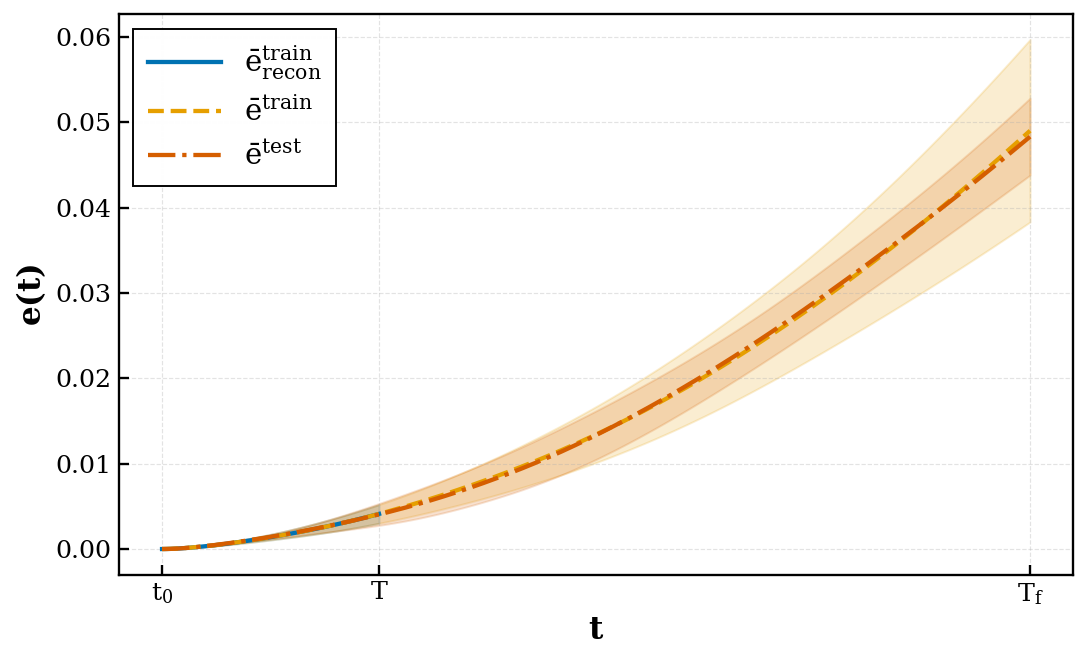

In [8]:
# Plot trajectory error over time
from ips_learning.visualization.error_analysis import ErrorAnalysisVisualizer
from ips_learning.visualization.utils import FigureRepository

error_viz = ErrorAnalysisVisualizer()
figure_repo = FigureRepository(root_dir=ARTIFACTS)

fig_error_time = error_viz.plot_error_over_time(
    t_recon=t_recon,
    recon_mean=recon_mean,
    recon_std=recon_std,
    t_train_full=t_train_full,
    train_full_mean=train_full_mean,
    train_full_std=train_full_std,
    t_test=t_test,
    test_mean=test_mean,
    test_std=test_std,
    train_horizon_end=FIT_END_TIME,
    title=None,#f"{SYSTEM_NAME.upper()} one-run trajectory error over time",
)

figure_repo.save(
    fig_error_time,
    system_name=SYSTEM_NAME,
    stage_name=FIGURE_STAGE,
    file_name="one_run_trajectory_error_over_time",
    close=False,
)


## One-run scalar metric summary table

In [9]:
metrics_csv_path = eval_dir / "one_run_metrics.csv"

one_run_df = pd.read_csv(metrics_csv_path)

one_run_df

,system_name,profile_name,fit_case_name,interaction_type,system_order,environment_variable,E_res,E_res_relative,E_phi,E_env,E_recon_train_fit,E_recon_train_full_0T,E_pred_train_full_TTf,E_recon_test_0T,E_pred_test_TTf,condition_number,rank,min_singular,max_singular,ridge_lambda
0,spp,spp_velocity_grid_clumps,dataset_train_fit_trial_001,energy,2,velocity,0.091578,0.032099,0.13635,0.087445,0.004117,0.004117,0.049023,0.004057,0.048328,26096.596529,210,0.000036,0.950771,NaN


In [10]:
summary_cols = [
    "system_name",
    "profile_name",
    "system_order",
    "environment_variable",
    "E_res",
    "E_res_relative",
    "E_phi",
    "E_phi_relative",
    "E_env",
    "E_env_relative",
    "E_recon_train_fit",
    "E_recon_train_full_0T",
    "E_pred_train_full_TTf",
    "E_recon_test_0T",
    "E_pred_test_TTf",
    "condition_number",
    "rank",
]

available_cols = [c for c in summary_cols if c in one_run_df.columns]
one_run_summary_table = one_run_df[available_cols].copy()

one_run_summary_table

,system_name,profile_name,system_order,environment_variable,E_res,E_res_relative,E_phi,E_env,E_recon_train_fit,E_recon_train_full_0T,E_pred_train_full_TTf,E_recon_test_0T,E_pred_test_TTf,condition_number,rank
0,spp,spp_velocity_grid_clumps,2,velocity,0.091578,0.032099,0.13635,0.087445,0.004117,0.004117,0.049023,0.004057,0.048328,26096.596529,210


In [11]:
table_repo = TableRepository(root_dir=ARTIFACTS)

saved_paths = table_repo.save(
    one_run_summary_table,
    system_name=SYSTEM_NAME,
    stage_name=FIGURE_STAGE,
    file_name="one_run_scalar_metric_summary",
    index=False,
    escape=False,
    float_format="%.4e",
    caption=f"{SYSTEM_NAME.upper()} one-run baseline metric summary.",
    label=f"tab:{SYSTEM_NAME}_one_run_metrics",
)

saved_paths

{'csv': PosixPath('./artifacts/spp/tables/step_6A/one_run_scalar_metric_summary.csv'),
 'tex': PosixPath('./artifacts/spp/tables/step_6A/one_run_scalar_metric_summary.tex')}

## Kernel and environment error figures

In [12]:
from ips_learning.visualization.function_error_analysis import FunctionErrorVisualizer
fun_viz = FunctionErrorVisualizer()

Saved: ./artifacts/spp/figures/step_6A/kernel_error_analysis.png


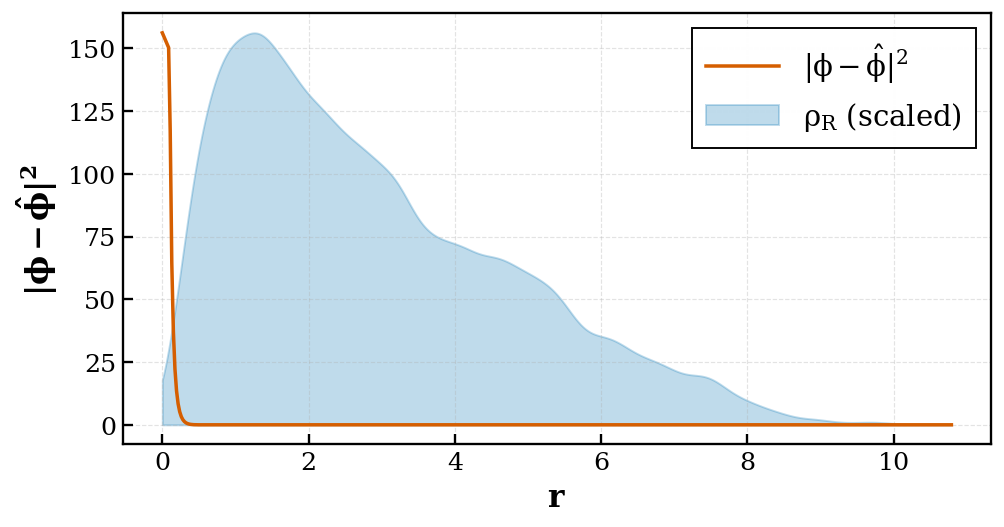

In [13]:
kernel_grid = arrays["kernel__r_eval"]
phi_true = arrays["kernel__phi_true"]
phi_hat = arrays["kernel__phi_hat"]

rho_r = None
if "kernel__weights" in arrays.files:
    rho_r = arrays["kernel__weights"]

fig_kernel = fun_viz.plot_kernel_error(
    r_grid=kernel_grid,
    phi_true=phi_true,
    phi_hat=phi_hat,
    density=rho_r,
    title=None,#rf"{SYSTEM_NAME.upper()} kernel recovery",
    labels={
        "phi_true": r"$\phi$",
        "phi_hat": r"$\hat{\phi}$",
        "error": r"$|\phi-\hat{\phi}|^2$",
        "density": r"$\rho_R$ (scaled)",
        "xlabel": r"$r$",
        "ylabel_top": r"$\phi(r)$",
        "ylabel_bottom": r"$|\phi-\hat{\phi}|^2$",
    },
)

path_kernel = figure_repo.save(
    fig_kernel,
    system_name=SYSTEM_NAME,
    stage_name=FIGURE_STAGE,
    file_name="kernel_error_analysis",
    close=False,
)

print("Saved:", path_kernel)

Saved: ./artifacts/spp/figures/step_6A/environment_error_analysis.png


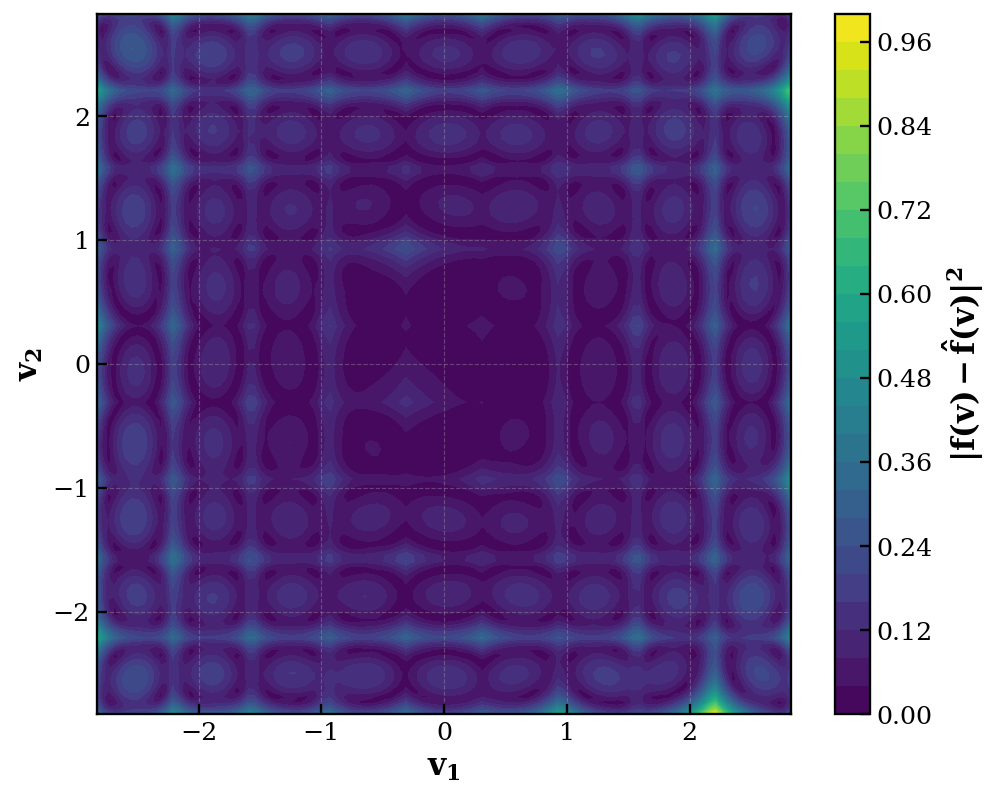

In [14]:
env_keys = arrays.files
z1_grid = arrays["environment__z1_grid"]

if "environment__z2_grid" in env_keys:
    z2_grid = arrays["environment__z2_grid"]
    rho_f =  arrays["environment__weights_grid"]
else:
    z2_grid = None
    rho_f =  arrays["environment__weights"]

f_true = arrays["environment__f_true_grid"]
f_hat = arrays["environment__f_hat_grid"]


if z2_grid is None:
    fig_env = fun_viz.plot_environment_error_1d(
    z_grid=z1_grid,
    f_true=f_true,
    f_hat=f_hat,
    density=rho_f,
    labels={
        "xlabel": r"$x$",
        "ylabel_top": r"$f(x)$",
        "ylabel_bottom": r"$|f-\hat f|^2$",
        "density": r"$\rho_X$ (scaled)",
    },
    )
else:
    fig_env = fun_viz.plot_environment_error(
    v1_grid=z1_grid,
    v2_grid=z2_grid,
    f_true=f_true,
    f_hat=f_hat,
    density=None,#rho_f,
    labels={
        "xlabel": r"$v_1$",
        "ylabel": r"$v_2$",
        "error_colorbar": r"$|f(v)-\hat f(v)|^2$",
    },
)

path_env = figure_repo.save(
    fig_env,
    system_name=SYSTEM_NAME,
    stage_name=FIGURE_STAGE,
    file_name="environment_error_analysis",
    close=False,
)

print("Saved:", path_env)

# Stage 6B:Repeated trials + N-scaling computation

In [15]:
FIGURE_STAGE = "step_6B"

REPEATED_EVAL_DIR = (
    ARTIFACTS
    / SYSTEM_NAME
    / "evaluations"
    / "repeated_trials"
)

TRIAL_METRICS_PATH = REPEATED_EVAL_DIR / "repeated_trial_metrics.csv"
FIT_SUMMARY_PATH = REPEATED_EVAL_DIR / "fit_diagnostic_summary.csv"
TRAJ_SUMMARY_PATH = REPEATED_EVAL_DIR / "trajectory_summary.csv"
FAILURE_SUMMARY_PATH = REPEATED_EVAL_DIR / "failure_summary.csv"

print("Repeated-trial metrics:", TRIAL_METRICS_PATH, TRIAL_METRICS_PATH.exists())
print("Fit summary:", FIT_SUMMARY_PATH, FIT_SUMMARY_PATH.exists())
print("Trajectory summary:", TRAJ_SUMMARY_PATH, TRAJ_SUMMARY_PATH.exists())
print("Failure summary:", FAILURE_SUMMARY_PATH, FAILURE_SUMMARY_PATH.exists())

Repeated-trial metrics: ./artifacts/spp/evaluations/repeated_trials/repeated_trial_metrics.csv True
Fit summary: ./artifacts/spp/evaluations/repeated_trials/fit_diagnostic_summary.csv True
Trajectory summary: ./artifacts/spp/evaluations/repeated_trials/trajectory_summary.csv True
Failure summary: ./artifacts/spp/evaluations/repeated_trials/failure_summary.csv True


In [16]:
trial_df = pd.read_csv(TRIAL_METRICS_PATH)
fit_summary = pd.read_csv(FIT_SUMMARY_PATH)
trajectory_summary = pd.read_csv(TRAJ_SUMMARY_PATH)
failure_summary = pd.read_csv(FAILURE_SUMMARY_PATH)

display(trial_df.head())
display(fit_summary)
display(trajectory_summary)
display(failure_summary)

,trial,system_name,profile_name,interaction_type,configured_system_order,failed,failure_message,system_order,environment_variable,train_fit_dataset,...,train_seen_mean_traj_TTf,train_seen_std_traj_TTf,test_unseen_mean_traj_0T,test_unseen_std_traj_0T,test_unseen_mean_traj_TTf,test_unseen_std_traj_TTf,test_4N_mean_traj_0T,test_4N_std_traj_0T,test_4N_mean_traj_TTf,test_4N_std_traj_TTf
0,1,spp,spp_velocity_grid_clumps,energy,2,False,NaN,2,velocity,dataset_train_fit_trial_001,...,0.051228,0.008707,0.004274,0.001101,0.050007,0.006341,0.007970,0.001440,0.056745,0.018580
1,2,spp,spp_velocity_grid_clumps,energy,2,False,NaN,2,velocity,dataset_train_fit_trial_002,...,0.049947,0.010111,0.004327,0.001157,0.053871,0.010784,0.007959,0.001734,0.047452,0.013829
2,3,spp,spp_velocity_grid_clumps,energy,2,False,NaN,2,velocity,dataset_train_fit_trial_003,...,0.048871,0.010176,0.004212,0.000996,0.045541,0.007799,0.007819,0.001345,0.051351,0.017109
3,4,spp,spp_velocity_grid_clumps,energy,2,False,NaN,2,velocity,dataset_train_fit_trial_004,...,0.054507,0.011737,0.004049,0.000934,0.050605,0.009805,0.007555,0.001437,0.052868,0.019277
4,5,spp,spp_velocity_grid_clumps,energy,2,False,NaN,2,velocity,dataset_train_fit_trial_005,...,0.047285,0.008042,0.004458,0.001206,0.044636,0.006542,0.007604,0.001412,0.048564,0.015392


,metric,mean,trial_std,mean_pm_trial_std,num_trials,system_name,profile_name,system_order,environment_variable,interaction_type
0,E_res,0.092022,0.000868,9.2022e-02 ± 8.6845e-04,10,spp,spp_velocity_grid_clumps,2,velocity,energy
1,E_res_relative,0.032506,0.000380,3.2506e-02 ± 3.8047e-04,10,spp,spp_velocity_grid_clumps,2,velocity,energy
2,E_phi,0.141803,0.005516,1.4180e-01 ± 5.5161e-03,10,spp,spp_velocity_grid_clumps,2,velocity,energy
3,E_phi_relative,0.119987,0.001993,1.1999e-01 ± 1.9935e-03,10,spp,spp_velocity_grid_clumps,2,velocity,energy
4,E_env,0.087479,0.000416,8.7479e-02 ± 4.1637e-04,10,spp,spp_velocity_grid_clumps,2,velocity,energy
5,E_env_relative,0.029742,0.000345,2.9742e-02 ± 3.4499e-04,10,spp,spp_velocity_grid_clumps,2,velocity,energy
6,condition_number,36098.468697,11604.708684,3.6098e+04 ± 1.1605e+04,10,spp,spp_velocity_grid_clumps,2,velocity,energy
7,rank,208.000000,0.000000,2.0800e+02 ± 0.0000e+00,10,spp,spp_velocity_grid_clumps,2,velocity,energy
8,min_singular,0.000032,0.000009,3.1784e-05 ± 9.0534e-06,10,spp,spp_velocity_grid_clumps,2,velocity,energy
9,max_singular,1.061083,0.130652,1.0611e+00 ± 1.3065e-01,10,spp,spp_velocity_grid_clumps,2,velocity,energy


,scenario,role,mean_traj_mean,mean_traj_trial_std,mean_traj_pm_trial_std,std_traj_mean,std_traj_trial_std,std_traj_pm_trial_std,num_trials_mean,num_trials_std
0,"train_fit [t0,T]",fit-window reconstruction,0.004292,0.000073,4.2917e-03 ± 7.3300e-05,0.001019,0.000105,1.0188e-03 ± 1.0479e-04,10,10
1,"train full [t0,T]",seen-IC pre-prediction interval,0.004292,0.000073,4.2917e-03 ± 7.3300e-05,0.001019,0.000105,1.0188e-03 ± 1.0478e-04,10,10
2,"train full [T,Tf]",seen-IC prediction,0.049692,0.002225,4.9692e-02 ± 2.2245e-03,0.009785,0.000988,9.7852e-03 ± 9.8778e-04,10,10
3,"test N [t0,T]",unseen-IC pre-prediction interval,0.004257,0.000129,4.2566e-03 ± 1.2914e-04,0.001133,0.000141,1.1333e-03 ± 1.4051e-04,10,10
4,"test N [T,Tf]",unseen-IC prediction,0.049394,0.002916,4.9394e-02 ± 2.9159e-03,0.008627,0.002362,8.6269e-03 ± 2.3622e-03,10,10
5,"test 4N [t0,T]",4N transfer pre-prediction interval,0.007886,0.000248,7.8865e-03 ± 2.4753e-04,0.001738,0.000480,1.7377e-03 ± 4.8045e-04,10,10
6,"test 4N [T,Tf]",4N transfer prediction,0.051675,0.003887,5.1675e-02 ± 3.8867e-03,0.016635,0.003383,1.6635e-02 ± 3.3828e-03,10,10


,num_trials,num_failed,failure_rate
0,10,0,0.0


In [17]:
required_cols = [
    "trial",
    "system_name",
    "profile_name",
    "system_order",
    "environment_variable",
    "interaction_type",
    "failed",
    "E_res",
    "E_res_relative",
    "E_phi",
    "E_phi_relative",
    "E_env",
    "E_env_relative",
    "condition_number",
    "rank",
    "train_fit_mean_traj_0T",
    "train_seen_mean_traj_0T",
    "train_seen_mean_traj_TTf",
    "test_unseen_mean_traj_0T",
    "test_unseen_mean_traj_TTf",
]

missing = [c for c in required_cols if c not in trial_df.columns]

if missing:
    print("Missing optional/required columns:", missing)
else:
    print("All expected repeated-trial columns are present.")

All expected repeated-trial columns are present.


## Save .tex tables

In [18]:
from ips_learning.visualization.utils import TableRepository

table_repo = TableRepository(root_dir=ARTIFACTS)

table_repo.save(
    fit_summary,
    system_name=SYSTEM_NAME,
    stage_name=FIGURE_STAGE,
    file_name="repeated_trial_fit_diagnostic_summary",
    index=False,
    escape=False,
    float_format="%.4e",
    caption=f"{SYSTEM_NAME.upper()} repeated-trial fit and function-error summary.",
    label=f"tab:{SYSTEM_NAME}_repeated_trial_fit_summary",
)

table_repo.save(
    trajectory_summary,
    system_name=SYSTEM_NAME,
    stage_name=FIGURE_STAGE,
    file_name="repeated_trial_trajectory_summary",
    index=False,
    escape=False,
    float_format="%.4e",
    caption=f"{SYSTEM_NAME.upper()} repeated-trial trajectory-error summary.",
    label=f"tab:{SYSTEM_NAME}_repeated_trial_trajectory_summary",
)

table_repo.save(
    failure_summary,
    system_name=SYSTEM_NAME,
    stage_name=FIGURE_STAGE,
    file_name="repeated_trial_failure_summary",
    index=False,
    escape=False,
    float_format="%.4e",
    caption=f"{SYSTEM_NAME.upper()} repeated-trial failure summary.",
    label=f"tab:{SYSTEM_NAME}_repeated_trial_failure_summary",
)

{'csv': PosixPath('./artifacts/spp/tables/step_6B/repeated_trial_failure_summary.csv'),
 'tex': PosixPath('./artifacts/spp/tables/step_6B/repeated_trial_failure_summary.tex')}

## 4N scalability phase portrait

In [19]:
from ips_learning.rollout.repository import RolloutRepository
from ips_learning.data.dataset_repository import DatasetRepository
from ips_learning.visualization.trajectories import TrajectoryVisualizer
from ips_learning.visualization.utils import FigureRepository

FIGURE_STAGE = "step_6B"

rollout_repo = RolloutRepository(root_dir=ARTIFACTS / "rollouts")
dataset_repo = DatasetRepository(root_dir=ARTIFACTS / "datasets")
figure_repo = FigureRepository(root_dir=ARTIFACTS)

traj_viz = TrajectoryVisualizer()

In [20]:
# Load 4N rollout artifact
artifact_4N = rollout_repo.load_case(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    case_name="trial_001",
    scenario="test_4N_prediction",
    rollout_name="trial_001_test_4N",
)
# Load 4N dataset
test_4N = dataset_repo.load(
    system_name=SYSTEM_NAME,
    split="test_4N",
    dataset_name="dataset_test_4N",
)

Saved: ./artifacts/spp/figures/step_6B/trial_001_4N_phase_portrait.png


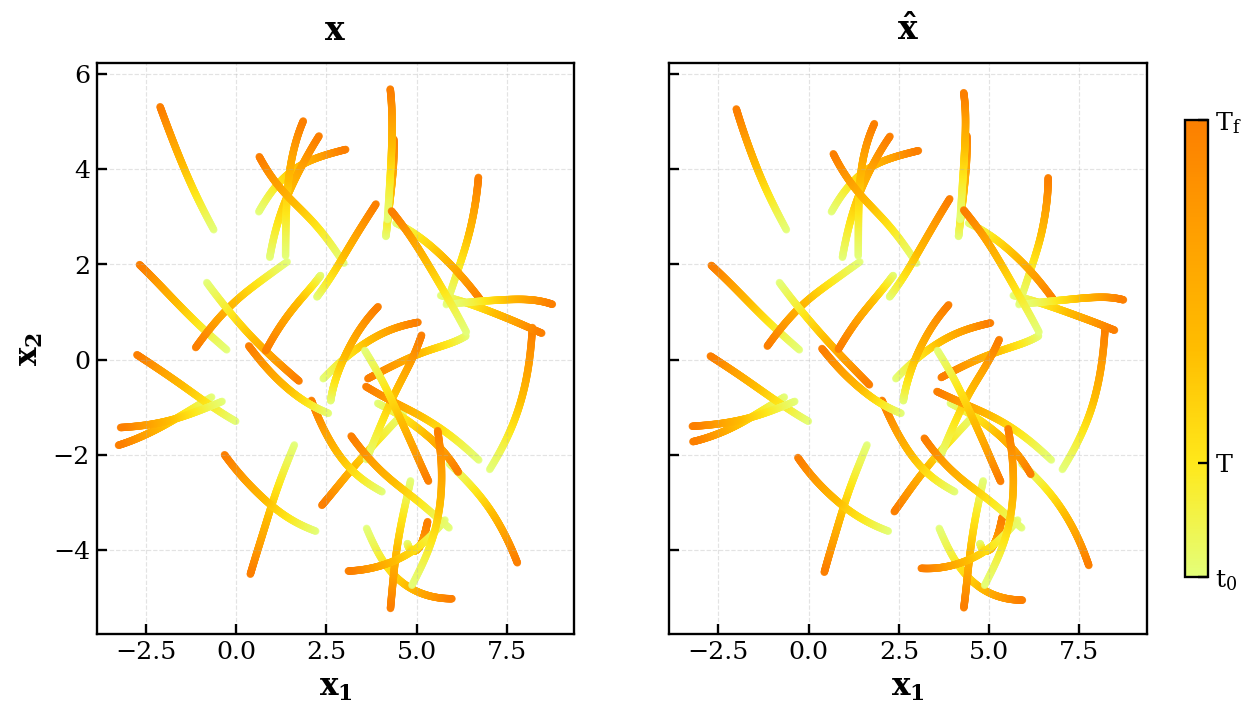

In [21]:
m = 0

X_true_4N = test_4N.X[m].transpose(1, 2, 0)
X_hat_4N = artifact_4N.X_hat[m].transpose(1, 2, 0)

D = X_true_4N.shape[1]

if D == 1:
    fig = traj_viz.plot_true_vs_learned_coordinate(
        t_true=test_4N.t,
        X_true=X_true_4N,
        t_hat=artifact_4N.t,
        X_hat=X_hat_4N,
        component=0,
        train_fit_end_pt=FIT_END_TIME,
        highlight_agent=0,
        title=None,#r"$4N$",
    )

    file_name = "trial_001_4N_coordinate"

elif D == 2:
    fig = traj_viz.plot_true_vs_learned_phase_portrait(
        t=test_4N.t,
        X_true=X_true_4N,
        X_hat=X_hat_4N,
        train_fit_end_pt=FIT_END_TIME,
        train_fit_mark=False,
        title_true=r"$x$",
        title_hat=r"$\hat{x}$",
    )

    file_name = "trial_001_4N_phase_portrait"

else:
    raise NotImplementedError(f"Trajectory visualization only supports D=1 or D=2, got D={D}.")

path = figure_repo.save(
    fig,
    system_name=SYSTEM_NAME,
    stage_name=FIGURE_STAGE,
    file_name=file_name,
    close=False,
)

print("Saved:", path)

## Mean +- STD for P and NP

In [22]:
NP_SUMMARY = np.load(
    ARTIFACTS
    / SYSTEM_NAME
    / "evaluations"
    / "repeated_trials"
    / "function_values"
    / "function_value_summary.npz"
)

P_SUMMARY = np.load(
    ARTIFACTS
    / SYSTEM_NAME
    / "evaluations"
    / "repeated_trials"
    / "parametric_f"
    / "function_values"
    / "function_value_summary.npz"
)

In [ ]:
from ips_learning.visualization.algorithm_mean_std_comparison import (
    AlgorithmMeanStdComparison,
)

from ips_learning.features.feature_repository import FeatureRepository
from ips_learning.bases.repository import BasisRepository
from ips_learning.statistics.density import build_empirical_error_density

viz = AlgorithmMeanStdComparison()

feature_repo = FeatureRepository(root_dir=ARTIFACTS / "features")
basis_repo = BasisRepository(root_dir=ARTIFACTS / "bases")

features = feature_repo.load(
    system_name=SYSTEM_NAME,
    split=TRAIN_FIT_SPLIT,
    feature_name=TRAIN_FIT_DATASET_NAME,
)

basis_bundle = basis_repo.load(
    system_name=SYSTEM_NAME,
    split=TRAIN_FIT_SPLIT,
    basis_name=TRAIN_FIT_DATASET_NAME,
)

# Empirical probability measure from the current training features.
empirical_density = build_empirical_error_density(
    features=features,
    localization_metadata=basis_bundle.localization_metadata,
)

# Repeated-trial summaries must be regenerated using the canonical grids.
if not np.allclose(
    NP_SUMMARY["kernel_grid"],
    empirical_density.r_grid,
):
    raise ValueError(
        "function_value_summary.npz uses an old kernel grid. "
        "Regenerate repeated-trial outputs with the cleaned pipeline."
    )

if not np.allclose(
    NP_SUMMARY["z1_grid"],
    empirical_density.z1_grid,
):
    raise ValueError(
        "function_value_summary.npz uses an old environment grid. "
        "Regenerate repeated-trial outputs with the cleaned pipeline."
    )

if "z2_grid" not in NP_SUMMARY.files:
    raise ValueError(
        "SPP repeated-trial summary must contain z2_grid."
    )

if not np.allclose(
    NP_SUMMARY["z2_grid"],
    empirical_density.z2_grid,
):
    raise ValueError(
        "function_value_summary.npz uses an old second environment grid. "
        "Regenerate repeated-trial outputs with the cleaned pipeline."
    )

train_density = empirical_density.kernel_weights

z1_grid = empirical_density.z1_grid
z2_grid = empirical_density.z2_grid

train_density_grid = empirical_density.environment_weights.reshape(
    len(z1_grid),
    len(z2_grid),
)

from ips_learning.systems.registry import (
    true_env_from_metadata,
    true_kernel_from_metadata,
)

true_phi = true_kernel_from_metadata(train_fit_dataset.metadata)
true_f = true_env_from_metadata(train_fit_dataset.metadata)


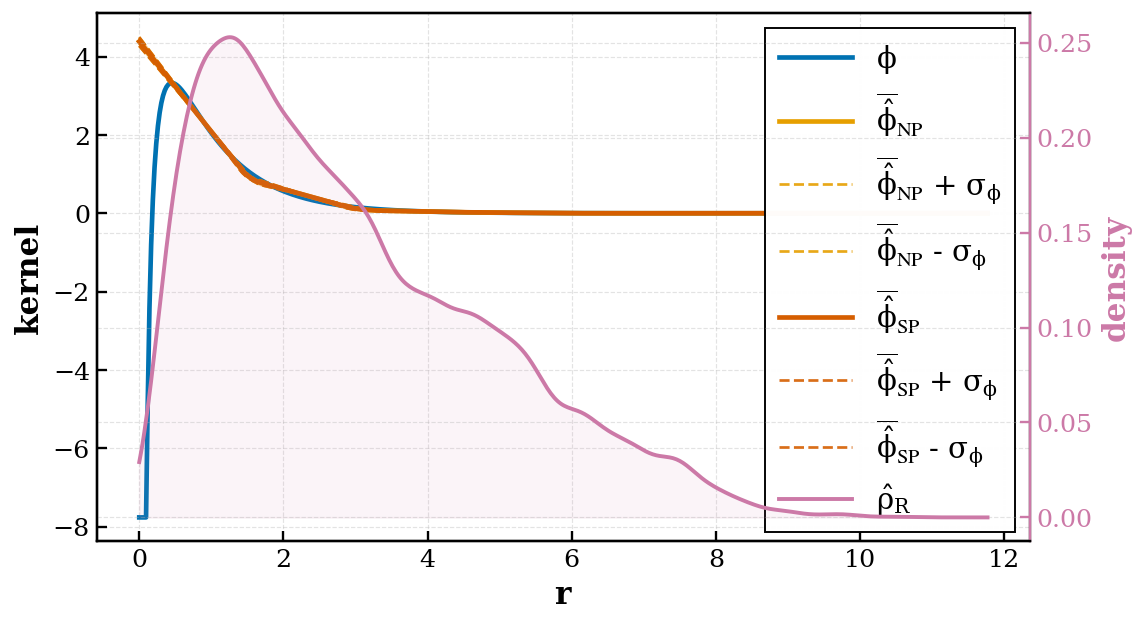

In [24]:
fig = viz.plot_kernel_mean_std_algorithm_comparison(
    true_kernel=true_phi,
    algorithm_summaries={
        "nonparametric_f": NP_SUMMARY,
        "parametric_f": P_SUMMARY,
    },
    train_density=train_density,
    labels={
        "title":None,
        "true_kernel_label": r"$\phi$",
         "x_label": r"$r$",
         "train_density_label": r"$\hat{\rho}_R$"
    },
)
figure_repo.save(
    fig,
    system_name=SYSTEM_NAME,
    stage_name="step_6B",
    file_name="kernel_mean_std_comparison",
)
fig

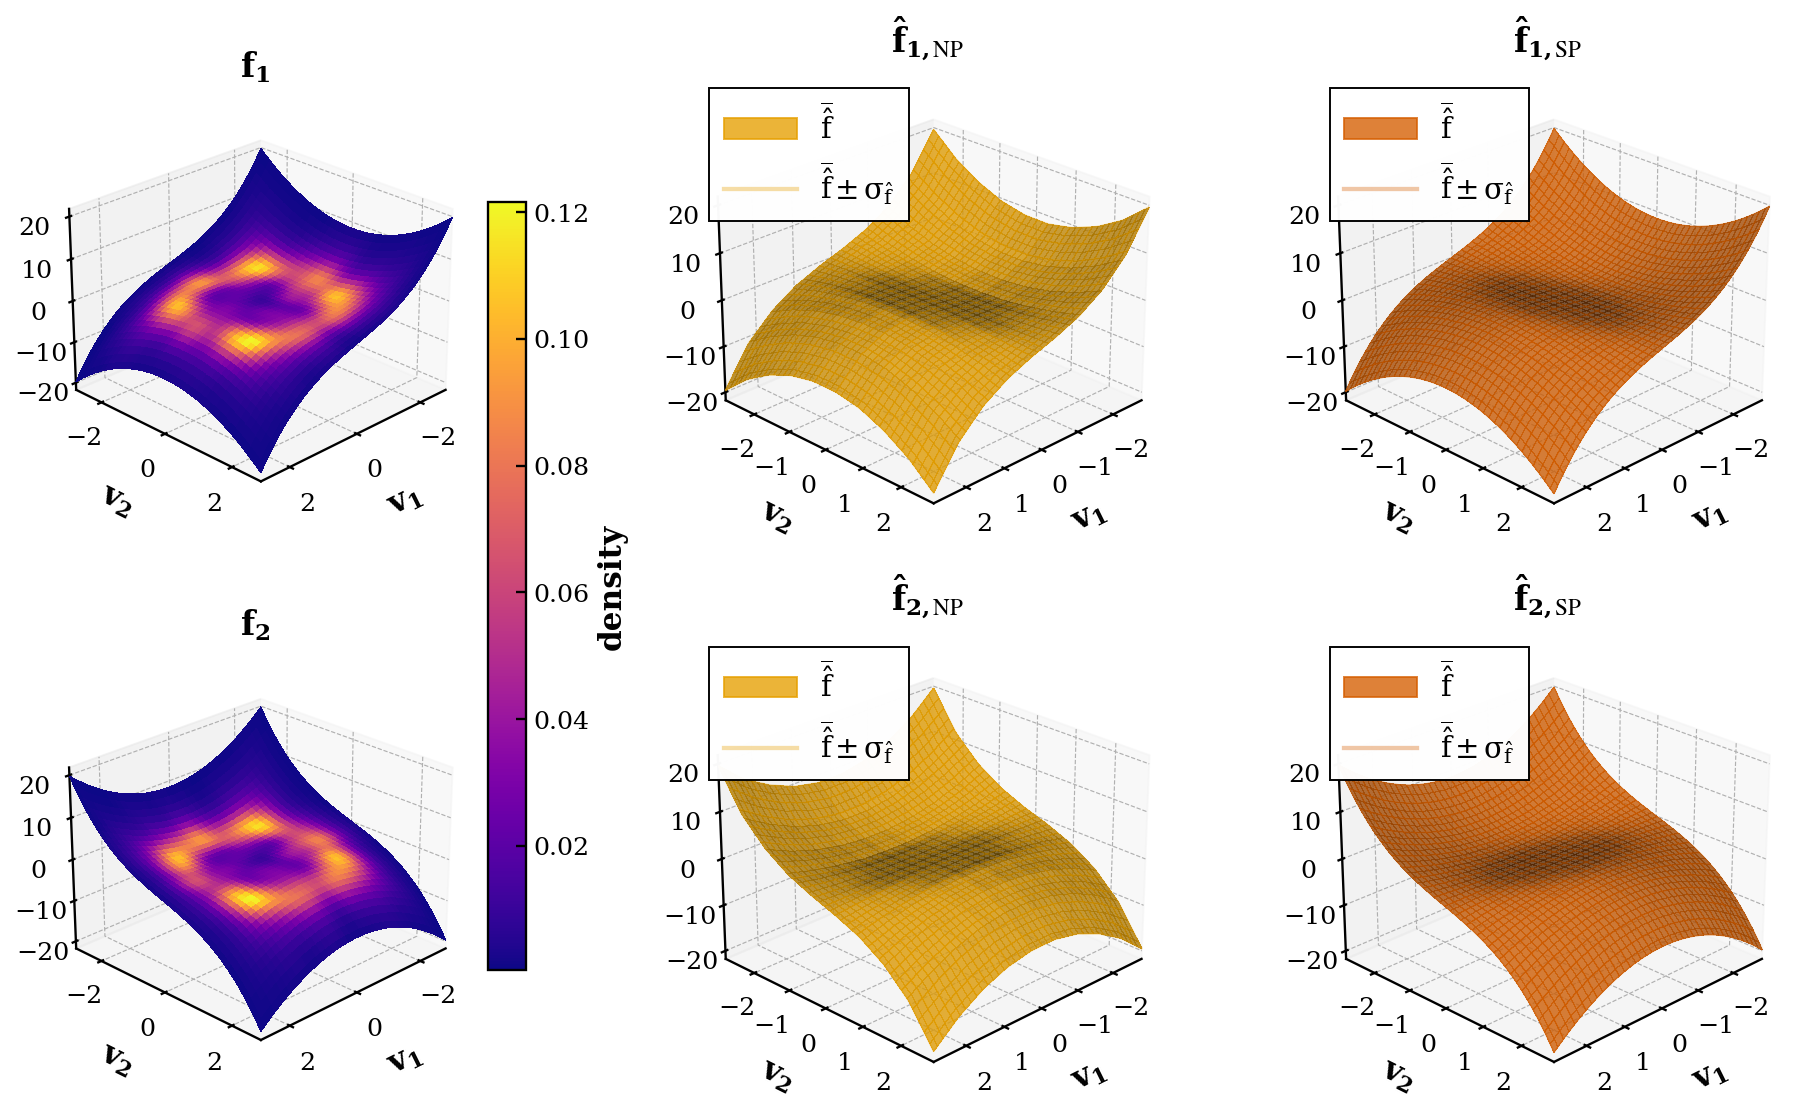

In [25]:
fig = viz.plot_environment_surfaces_2d_mean_std(
    true_env=true_f,
    reference_density=train_density_grid,
    algorithm_summaries={
        "nonparametric_f": NP_SUMMARY,
        "parametric_f": P_SUMMARY,
    },
    environment_variable="v",
)
figure_repo.save(
    fig,
    system_name=SYSTEM_NAME,
    stage_name="step_6B",
    file_name="environment_surfaces_2d_mean_std",
)
fig

# Stage 6C: ML sweep analysis

In [26]:
FIGURE_STAGE = "step_6C"

ml_eval_dir = ARTIFACTS / SYSTEM_NAME / "evaluations" / "ML_sweep"
ml_metrics_path = ml_eval_dir / "ML_sweep_metrics.csv"

df_ml = pd.read_csv(ml_metrics_path)

df_ml.head()

,M,L,system_order,environment_variable,L_fit,L_full,case_name,system_name,profile_name,interaction_type,...,E_env_relative,cond_A,cond_A_phi,cond_A_f,cond_A_phi_f,cond_A_f_phi,rank,min_singular,max_singular,ridge_lambda
0,1,13,2,velocity,13,49,M_001_L_013,spp,spp_velocity_grid_clumps,energy,...,0.364247,inf,54450.656373,inf,430.370123,430.370123,210,8.745520e-17,0.940718,1.000000e-08
1,1,25,2,velocity,25,97,M_001_L_025,spp,spp_velocity_grid_clumps,energy,...,0.588020,inf,16599.869559,inf,306.657191,306.657191,210,8.763620e-17,1.021637,1.000000e-08
2,1,51,2,velocity,51,201,M_001_L_051,spp,spp_velocity_grid_clumps,energy,...,9.190843,inf,40312.187015,inf,354.346848,354.346848,210,1.902910e-16,2.493911,1.000000e-08
3,1,100,2,velocity,100,396,M_001_L_100,spp,spp_velocity_grid_clumps,energy,...,2.612863,inf,23530.546000,inf,215.491298,215.491298,210,1.613436e-16,1.813099,1.000000e-08
4,1,200,2,velocity,200,797,M_001_L_200,spp,spp_velocity_grid_clumps,energy,...,1.049981,inf,17448.513066,inf,385.409899,385.409899,210,8.445589e-18,0.203780,1.000000e-08


In [27]:
from ips_learning.visualization.utils import TableRepository
# save the fill table
table_repo = TableRepository(root_dir=ARTIFACTS)

table_repo.save(
    df_ml,
    system_name=SYSTEM_NAME,
    stage_name=FIGURE_STAGE,
    file_name="ML_sweep_metrics_full",
    index=False,
    escape=False,
    float_format="%.4e",
    caption=f"{SYSTEM_NAME.upper()} M/L sweep metrics.",
    label=f"tab:{SYSTEM_NAME}_ML_sweep_metrics",
)

{'csv': PosixPath('./artifacts/spp/tables/step_6C/ML_sweep_metrics_full.csv'),
 'tex': PosixPath('./artifacts/spp/tables/step_6C/ML_sweep_metrics_full.tex')}

## heatmaps

In [ ]:
# Helper for heatmaps
import numpy as np
import matplotlib.pyplot as plt

from ips_learning.visualization.utils import FigureRepository
from ips_learning.visualization.style import apply_paper_style

apply_paper_style()
figure_repo = FigureRepository(root_dir=ARTIFACTS)


def pivot_metric(df, metric):
    return df.pivot(index="M", columns="L", values=metric).sort_index()


def plot_ml_heatmap(df, metric, log_scale=True, cbar_label=None ):
    Z_df = pivot_metric(df, metric)
    Z = Z_df.values.astype(float)

    fig, ax = plt.subplots(figsize=(7.4, 5.6))

    if log_scale:
        Z_plot = np.log10(np.where(Z > 0, Z, np.nan))
        cbar_label = rf"$\log_{{10}}$({cbar_label})"
    else:
        Z_plot = Z
        cbar_label = metric

    im = ax.imshow(
        Z_plot,
        origin="lower",
        aspect="auto",
    )

    ax.set_xticks(np.arange(len(Z_df.columns)))
    ax.set_xticklabels(Z_df.columns)

    ax.set_yticks(np.arange(len(Z_df.index)))
    ax.set_yticklabels(Z_df.index)

    ax.set_xlabel(r"$L$")
    ax.set_ylabel(r"$M$")

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(cbar_label)
    ax.grid(False)

    return fig

<>:5: SyntaxWarning: invalid escape sequence '\p'
<>:5: SyntaxWarning: invalid escape sequence '\p'
/var/folders/t_/xpkf3pmd5kv80t9trjbv1n1r0000gn/T/ipykernel_52815/2434285329.py:5: SyntaxWarning: invalid escape sequence '\p'
  labels = ["$E_{\phi}$", "$E_{f}$"]


Saved: ./artifacts/spp/figures/step_6C/ML_sweep_heatmap_E_phi_relative.png
Saved: ./artifacts/spp/figures/step_6C/ML_sweep_heatmap_E_env_relative.png


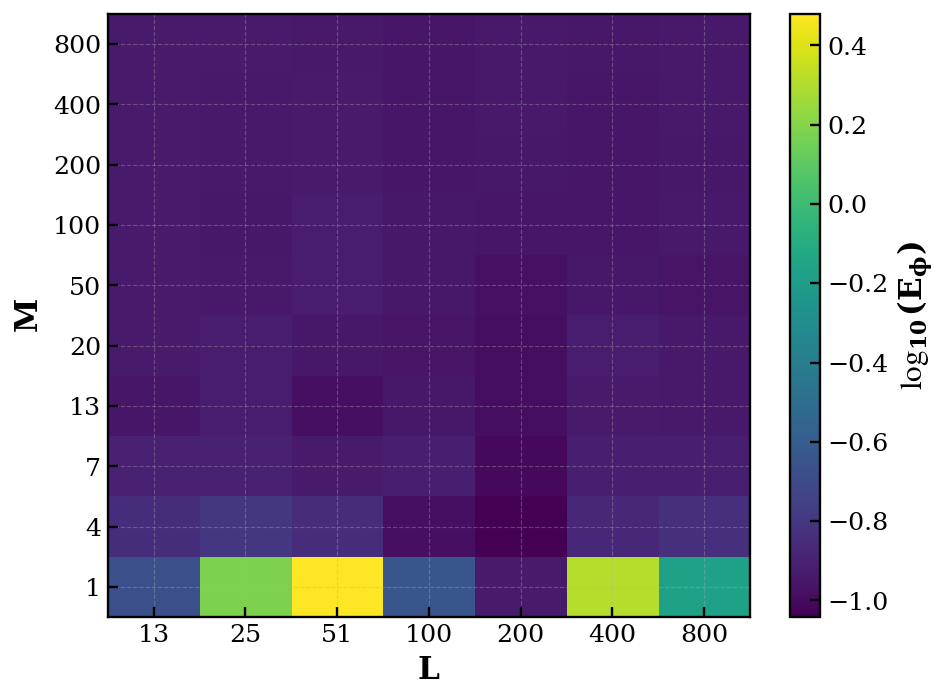

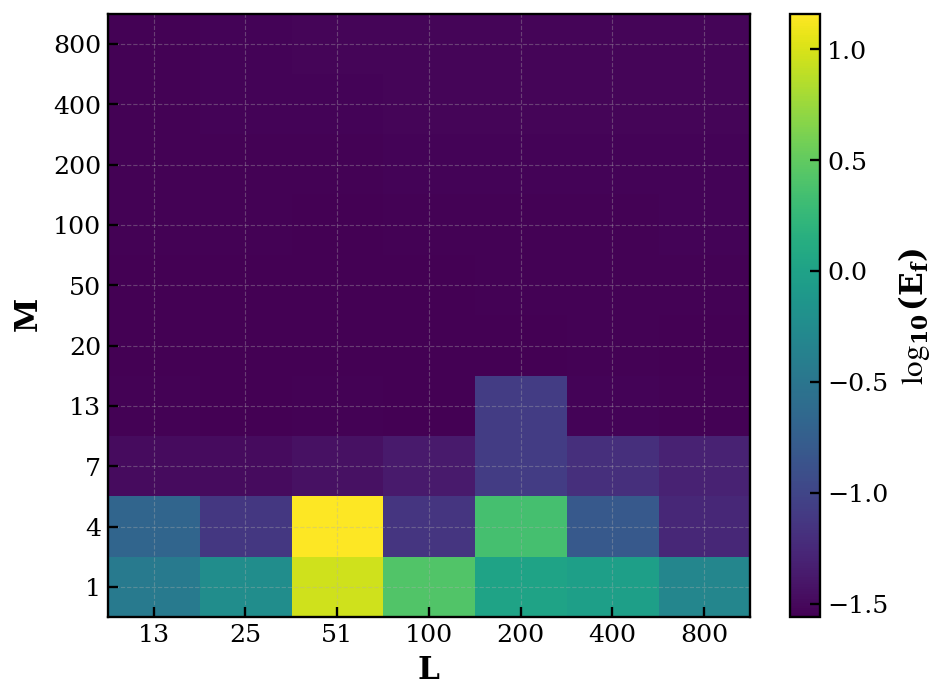

In [29]:
core_metrics = [
    "E_phi_relative",
    "E_env_relative",
]
labels = ["$E_{\phi}$", "$E_{f}$"]

for index, metric in enumerate(core_metrics):
    if metric not in df_ml.columns:
        print("Skipping missing metric:", metric)
        continue

    fig = plot_ml_heatmap(
        df_ml,
        metric=metric,
        cbar_label=labels[index],
        log_scale=True,
    )

    path = figure_repo.save(
        fig,
        system_name=SYSTEM_NAME,
        stage_name=FIGURE_STAGE,
        file_name=f"ML_sweep_heatmap_{metric}",
        close=False,
    )

    print("Saved:", path)

## plots versus M for fixed L

In [30]:
# plots versus M for fixed L

def plot_err_versus_M_for_fixed_L(df_ml, metric, ylabel):
   
    fig, ax = plt.subplots(figsize=(8.4, 5.0))

    for L_value, group in df_ml.groupby("L"):
        group = group.sort_values("M")
        ax.plot(
            group["M"],
            group[metric],
            marker="o",
            linewidth=2.0,
            label=f"L={L_value}",
        )

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$M$")
    ax.set_ylabel(rf"{ylabel}")
    ax.legend(loc="best")

    path = figure_repo.save(
        fig,
        system_name=SYSTEM_NAME,
        stage_name=FIGURE_STAGE,
        file_name=f"ML_sweep_{metric}_vs_M_by_L",
        close=False,
    )

    print("Saved:", path)
    return fig

<>:5: SyntaxWarning: invalid escape sequence '\p'
<>:5: SyntaxWarning: invalid escape sequence '\p'
/var/folders/t_/xpkf3pmd5kv80t9trjbv1n1r0000gn/T/ipykernel_52815/3589170984.py:5: SyntaxWarning: invalid escape sequence '\p'
  labels = [ "$E_{\phi}$", "$E_{f}$"]


Saved: ./artifacts/spp/figures/step_6C/ML_sweep_E_phi_relative_vs_M_by_L.png
Saved: ./artifacts/spp/figures/step_6C/ML_sweep_E_env_relative_vs_M_by_L.png


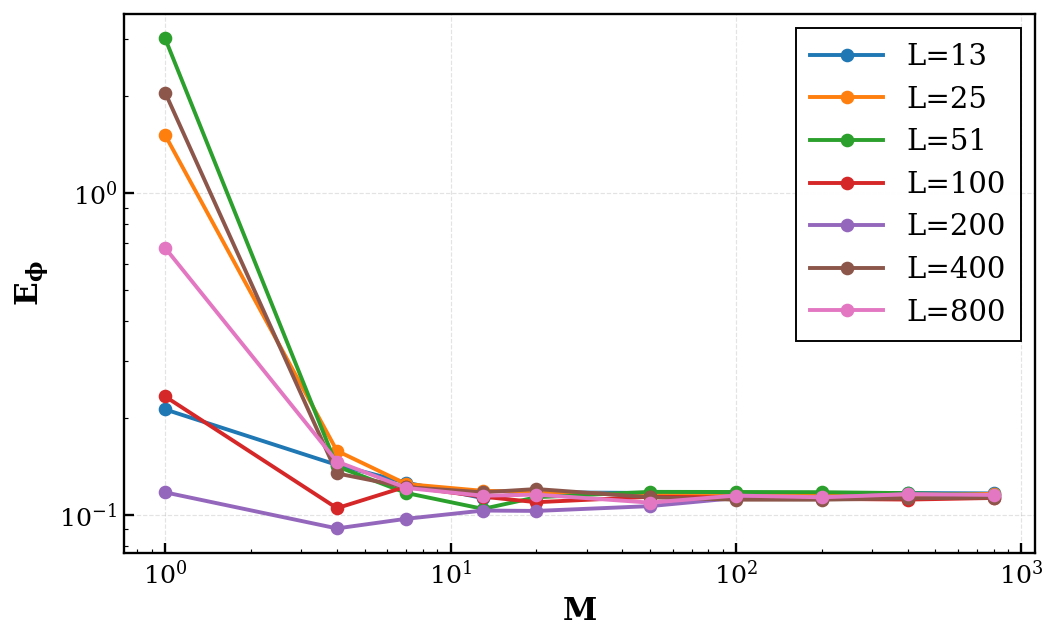

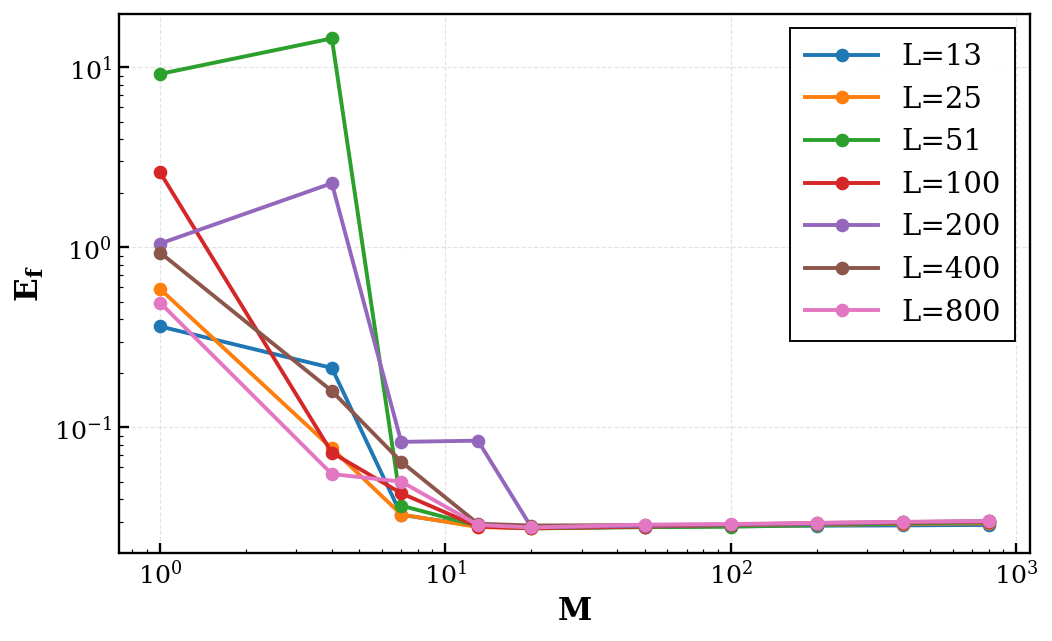

In [31]:
core_metrics = [
    "E_phi_relative",
    "E_env_relative",
]
labels = [ "$E_{\phi}$", "$E_{f}$"]

for index, metric in enumerate(core_metrics):
    if metric not in df_ml.columns:
        print("Skipping missing metric:", metric)
        continue

    fig = plot_err_versus_M_for_fixed_L(
        df_ml,
        metric=metric,
        ylabel=labels[index],
    )

# Stage 6C-2: M L Trial sweep anlysis

In [27]:
FIGURE_STAGE = "step_6C2"

ml_eval_dir = ARTIFACTS / SYSTEM_NAME / "evaluations" / "ML_sweep"
trial_metrics_path = (
    ml_eval_dir
    / "ML_sweep_trial_metrics.csv"
)

summary_metrics_path = (
    ml_eval_dir
    / "ML_sweep_metrics_mean_std.csv"
)

# One row per (trial, M, L).
df_ml_trials = pd.read_csv(trial_metrics_path)

# One row per (M, L), containing statistics across trials.
df_ml = pd.read_csv(summary_metrics_path)

print("Trial-level rows:", len(df_ml_trials))
print("Mean/std rows:", len(df_ml))

display(df_ml.head())

Trial-level rows: 250
Mean/std rows: 25


,M,L,n_trials_requested,n_trials_recorded,n_successful_trials,n_failed_trials,trial_base_seed_count,trial_base_seed_mean,trial_base_seed_std,E_res_count,...,rank_std,min_singular_count,min_singular_mean,min_singular_std,max_singular_count,max_singular_mean,max_singular_std,ridge_lambda_count,ridge_lambda_mean,ridge_lambda_std
0,1,51,10,10,10,0,10,450000909.0,3.027650e+08,10,...,0.0,10,7.821193e-17,7.471852e-17,10,0.956560,0.931953,10,1.000000e-08,0.0
1,1,101,10,10,10,0,10,450000909.0,3.027650e+08,10,...,0.0,10,8.491829e-17,7.416358e-17,10,0.962134,0.818802,10,1.000000e-08,0.0
2,1,201,10,10,10,0,10,450000909.0,3.027650e+08,10,...,0.0,10,4.441120e-17,3.045769e-17,10,0.509393,0.322683,10,1.000000e-08,0.0
3,1,401,10,10,10,0,10,450000909.0,3.027650e+08,10,...,0.0,10,7.213429e-17,1.003622e-16,10,0.928317,1.131918,10,1.000000e-08,0.0
4,1,801,10,10,10,0,10,450000909.0,3.027650e+08,10,...,0.0,10,6.669841e-17,3.608843e-17,10,0.777921,0.374758,10,1.000000e-08,0.0


In [28]:
def plot_mean_error_versus_M_for_fixed_L(
    df_ml,
    *,
    metric,
    ylabel,
    file_stem,
):
    """
    Plot a repeated-trial mean error against M for each fixed L.
    """
    fig, ax = plt.subplots(figsize=(8.4, 5.0))

    for L_value, group in df_ml.groupby("L"):
        group = group.sort_values("M").copy()

        group[metric] = pd.to_numeric(
            group[metric],
            errors="coerce",
        )

        # Log axes require finite positive values.
        valid = (
            np.isfinite(group["M"])
            & np.isfinite(group[metric])
            & (group["M"] > 0)
            & (group[metric] > 0)
        )

        group = group.loc[valid]

        if group.empty:
            print(
                f"Skipping L={L_value}: "
                f"no positive finite values for {metric}."
            )
            continue

        ax.plot(
            group["M"],
            group[metric],
            marker="o",
            linewidth=2.0,
            label=rf"$L={L_value}$",
        )

    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_xlabel(r"$M$")
    ax.set_ylabel(ylabel)

    ax.legend(
        loc="best",
        frameon=True,
    )

    fig.tight_layout()

    path = figure_repo.save(
        fig,
        system_name=SYSTEM_NAME,
        stage_name=FIGURE_STAGE,

        # Keep the original output name.
        file_name=(
            f"ML_sweep_{file_stem}_vs_M_by_L"
        ),
        close=False,
    )

    print("Saved:", path)

    return fig

Saved: ./artifacts/spp/figures/step_6C2/ML_sweep_heatmap_trial_E_phi_relative.png
Saved: ./artifacts/spp/figures/step_6C2/ML_sweep_heatmap_trial_E_env_relative.png


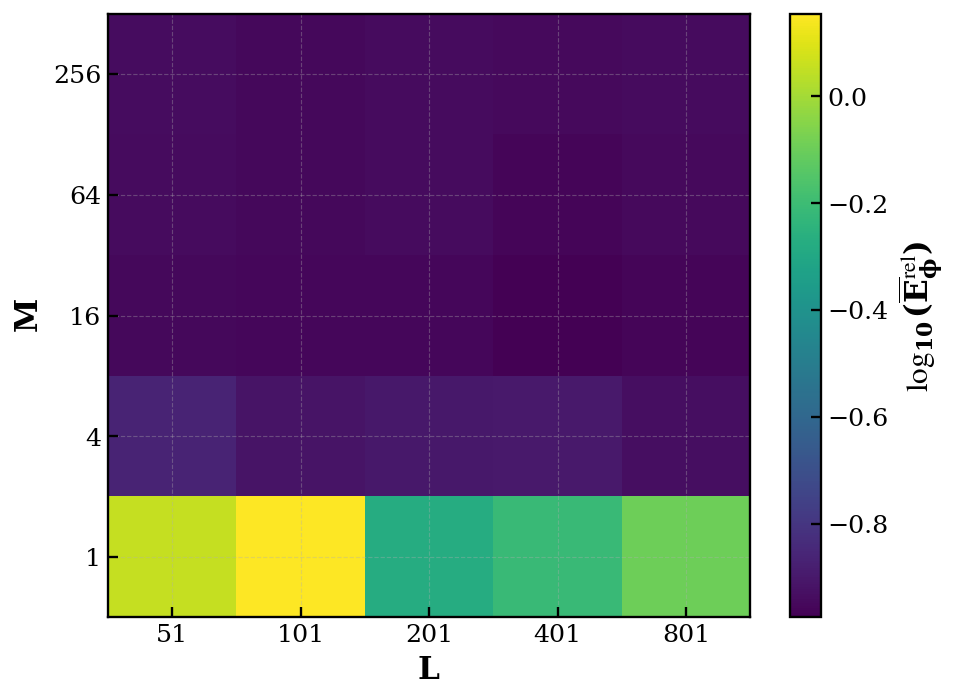

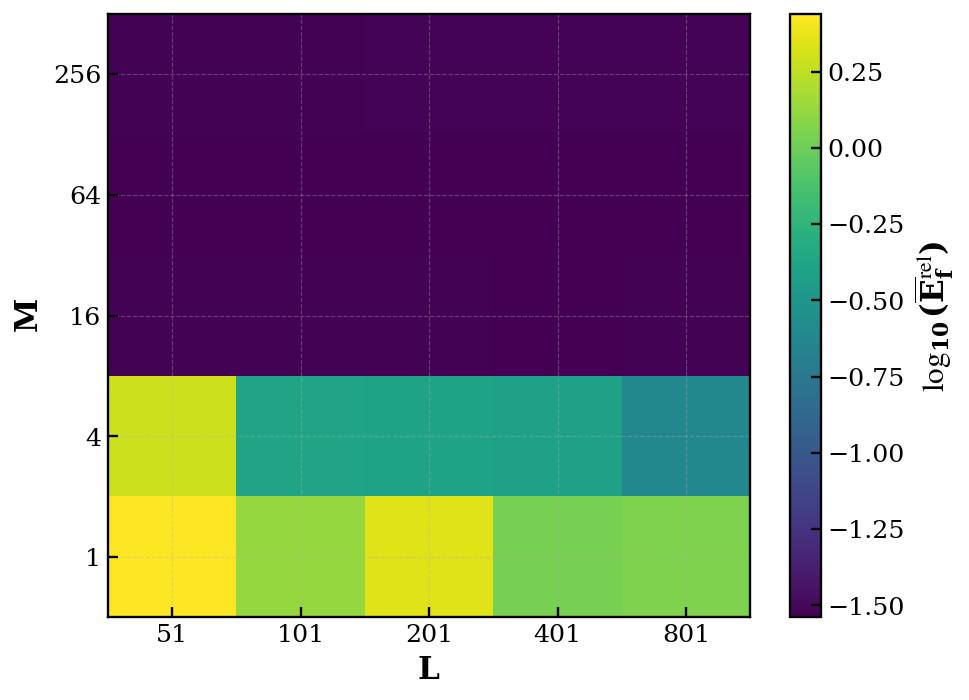

In [29]:
# --------------------------------------------------
# Heatmaps of mean relative errors across trials
# --------------------------------------------------
mean_metric_specs = [
    {
        "column": "E_phi_relative_mean",
        "label": r"$\overline{E}_{\phi}^{\mathrm{rel}}$",
        "file_stem": "E_phi_relative",
    },
    {
        "column": "E_env_relative_mean",
        "label": r"$\overline{E}_{f}^{\mathrm{rel}}$",
        "file_stem": "E_env_relative",
    },
]

for spec in mean_metric_specs:
    metric = spec["column"]

    if metric not in df_ml.columns:
        print("Skipping missing metric:", metric)
        continue

    fig = plot_ml_heatmap(
        df_ml,
        metric=metric,
        cbar_label=spec["label"],
        log_scale=True,
    )

    path = figure_repo.save(
        fig,
        system_name=SYSTEM_NAME,
        stage_name=FIGURE_STAGE,

        # Keep the original filename so existing LaTeX figure
        # references do not need to change.
        file_name=(
            f"ML_sweep_heatmap_trial_{spec['file_stem']}"
        ),
        close=False,
    )

    print("Saved:", path)

Saved: ./artifacts/spp/figures/step_6C2/ML_sweep_E_phi_relative_vs_M_by_L.png
Saved: ./artifacts/spp/figures/step_6C2/ML_sweep_E_env_relative_vs_M_by_L.png


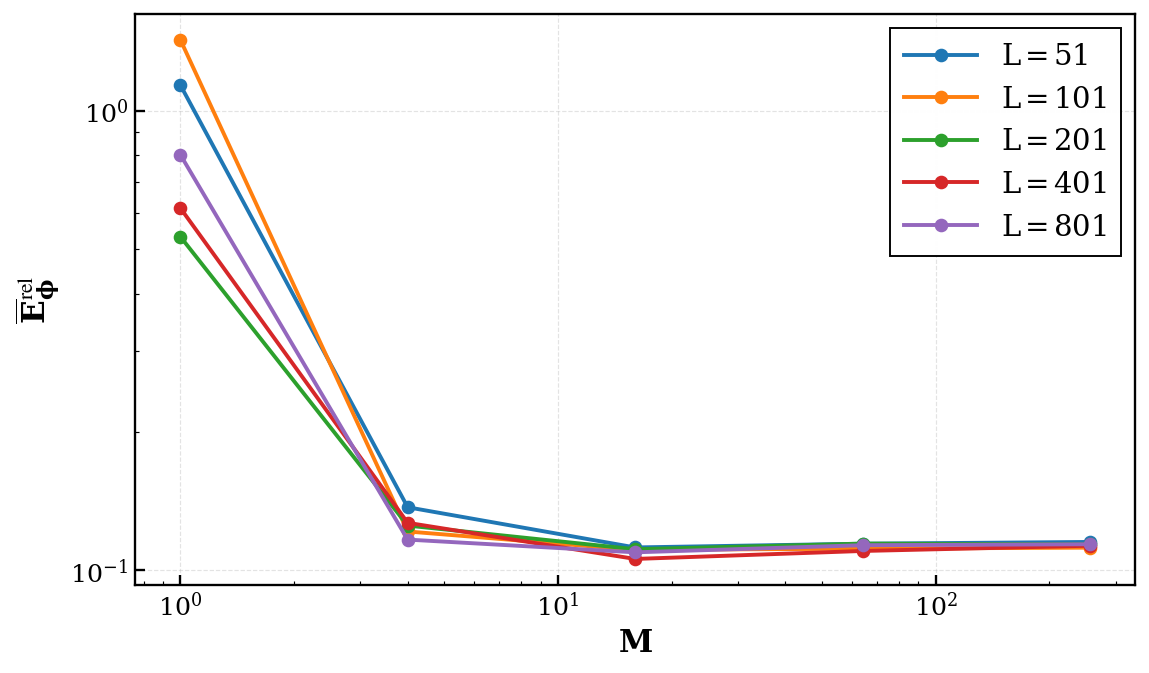

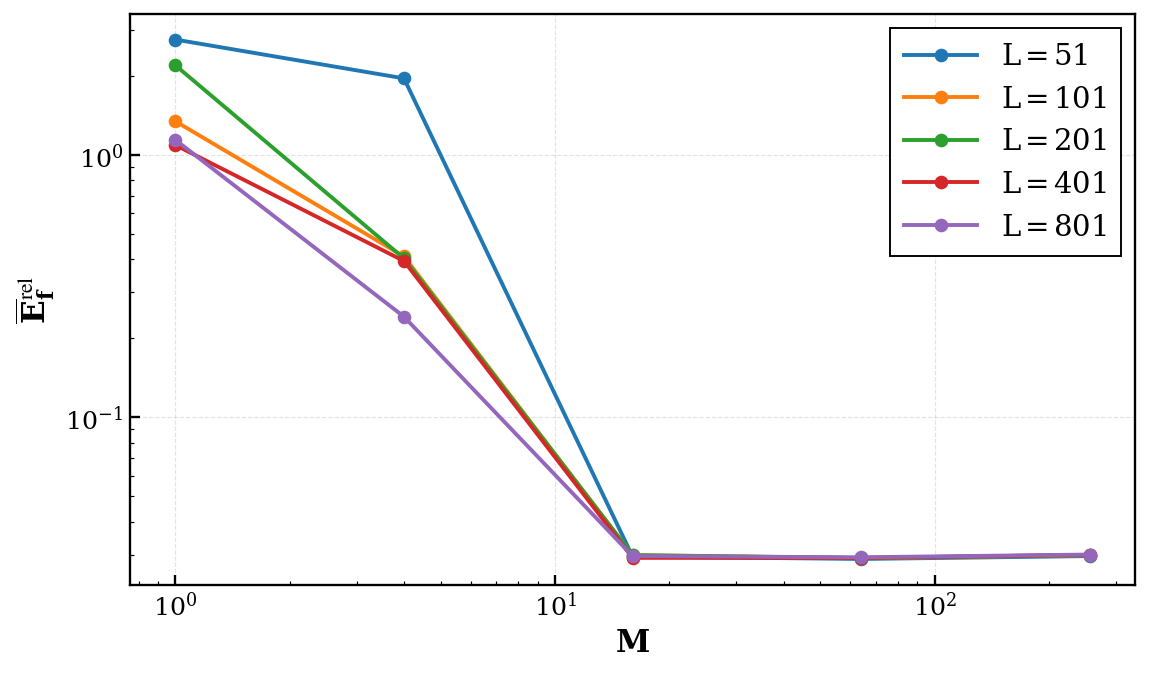

In [30]:
# --------------------------------------------------
# Mean relative error versus M for each fixed L
# --------------------------------------------------
mean_metric_specs = [
    {
        "column": "E_phi_relative_mean",
        "ylabel": (
            r"$\overline{E}_{\phi}^{\mathrm{rel}}$"
        ),
        "file_stem": "E_phi_relative",
    },
    {
        "column": "E_env_relative_mean",
        "ylabel": (
            r"$\overline{E}_{f}^{\mathrm{rel}}$"
        ),
        "file_stem": "E_env_relative",
    },
]

for spec in mean_metric_specs:
    metric = spec["column"]

    if metric not in df_ml.columns:
        print("Skipping missing metric:", metric)
        continue

    fig = plot_mean_error_versus_M_for_fixed_L(
        df_ml,
        metric=metric,
        ylabel=spec["ylabel"],
        file_stem=spec["file_stem"],
    )

In [31]:
# --------------------------------------------------
# Stage 6C: LaTeX table of relative errors
# Mean ± sample standard deviation across trials
# --------------------------------------------------

required_error_columns = [
    "M",
    "L",
    "E_phi_relative_mean",
    "E_phi_relative_std",
    "E_env_relative_mean",
    "E_env_relative_std",
]

missing_columns = [
    column
    for column in required_error_columns
    if column not in df_ml.columns
]

if missing_columns:
    raise ValueError(
        "Missing columns required for the M/L error table: "
        f"{missing_columns}"
    )


def format_mean_std(mean_value, std_value) -> str:
    """
    Format one table entry as mean ± standard deviation.

    Uses siunitx scientific notation.
    """
    if pd.isna(mean_value):
        return r"--"

    if pd.isna(std_value):
        return rf"$\num{{{mean_value:.4e}}}$"

    return (
        rf"$\num{{{mean_value:.4e}}}"
        rf"\pm"
        rf"\num{{{std_value:.4e}}}$"
    )


ml_relative_error_table = (
    df_ml[
        required_error_columns
    ]
    .sort_values(["M", "L"])
    .reset_index(drop=True)
    .copy()
)

ml_relative_error_table[
    r"$E_{\phi}^{\mathrm{rel}}$"
] = ml_relative_error_table.apply(
    lambda row: format_mean_std(
        row["E_phi_relative_mean"],
        row["E_phi_relative_std"],
    ),
    axis=1,
)

ml_relative_error_table[
    r"$E_{f}^{\mathrm{rel}}$"
] = ml_relative_error_table.apply(
    lambda row: format_mean_std(
        row["E_env_relative_mean"],
        row["E_env_relative_std"],
    ),
    axis=1,
)

# Keep only M, L, and the two requested relative-error metrics.
ml_relative_error_table = ml_relative_error_table[
    [
        "M",
        "L",
        r"$E_{\phi}^{\mathrm{rel}}$",
        r"$E_{f}^{\mathrm{rel}}$",
    ]
]

display(ml_relative_error_table.head())

,M,L,$E_{\phi}^{\mathrm{rel}}$,$E_{f}^{\mathrm{rel}}$
0,1,51,$\num{1.1381e+00}\pm\num{1.2043e+00}$,$\num{2.7564e+00}\pm\num{3.3192e+00}$
1,1,101,$\num{1.4278e+00}\pm\num{1.7454e+00}$,$\num{1.3453e+00}\pm\num{1.0674e+00}$
2,1,201,$\num{5.3246e-01}\pm\num{5.6657e-01}$,$\num{2.1987e+00}\pm\num{2.1506e+00}$
3,1,401,$\num{6.1445e-01}\pm\num{5.5824e-01}$,$\num{1.0916e+00}\pm\num{1.5755e+00}$
4,1,801,$\num{8.0262e-01}\pm\num{3.6660e-01}$,$\num{1.1428e+00}\pm\num{5.8255e-01}$


In [32]:
# --------------------------------------------------
# Save as a multipage LaTeX longtable
# --------------------------------------------------

table_output_dir = table_repo.stage_dir(
    system_name=SYSTEM_NAME,
    stage_name=FIGURE_STAGE,
)

tex_path = (
    table_output_dir
    / "ML_sweep_relative_errors_mean_std.tex"
)

caption = (
    "(SPP model) SPP model relative interaction "
    "kernel and environmental force errors for different $M$ "
    "(number of replicates) and $L$ (number of time samples). "
    "Each entry reports the mean $\pm$ sample standard deviation "
    "over $T_r = 10$ independent learning trials."
)

label = (
    f"tab:{SYSTEM_NAME}_ML_sweep_relative_errors_mean_std"
)

latex_text = ml_relative_error_table.to_latex(
    index=False,
    escape=False,
    longtable=True,
    column_format="rrcc",
    caption=caption,
    label=label,
)

tex_path.write_text(
    latex_text,
    encoding="utf-8",
)

print("Saved LaTeX table:", tex_path)

Saved LaTeX table: ./artifacts/spp/tables/step_6C2/ML_sweep_relative_errors_mean_std.tex


# Stage 6D: Noise Sweep

In [33]:
FIGURE_STAGE = "step_6D"
TRAIN_FIT_SPLIT = "train_fit"
TRAIN_FIT_DATASET_NAME = "dataset_train_fit_trial_001"

TRAIN_SPLIT = "train"

TRAIN_DATASET_NAME = "dataset_train_trial_001"

FIT_END_TIME = 0.5  # SPP

NOISE_LEVELS = (0.0, 0.01, 0.03, 0.05, 0.10)

NOISE_TYPE = "multiplicative_uniform"
NOISE_SEED_BASE = 9000

noise_eval_dir = ARTIFACTS / SYSTEM_NAME / "evaluations" / "noise_sweep"
noise_metrics_path = noise_eval_dir / "noise_sweep_metrics.csv"

df_noise = pd.read_csv(noise_metrics_path)
df_noise = df_noise.sort_values("noise_level").reset_index(drop=True)

df_noise

,noise_level,system_order,environment_variable,E_res,E_phi,E_phi_relative,E_env,E_env_relative,E_recon_train_fit,E_pred_train_same_ic,E_test_preT_unseen_ic,E_test_pred_unseen_ic,cond_A,rollout_failed,failure_message
0,0.00,2,velocity,0.091578,0.136350,0.119638,0.087445,0.029556,0.004117,0.049023,0.004057,0.048328,26096.596529,False,NaN
1,0.01,2,velocity,0.108022,0.136612,0.119867,0.089513,0.030255,0.027833,0.049815,0.004197,0.048488,31326.743210,False,NaN
2,0.03,2,velocity,0.189848,0.136407,0.119687,0.097470,0.032945,0.081954,0.051881,0.004617,0.048368,55974.220162,False,NaN
3,0.05,2,velocity,0.294347,0.136947,0.120161,0.116772,0.039469,0.138680,0.052786,0.005317,0.049815,81030.387345,False,NaN
4,0.10,2,velocity,0.550917,0.147780,0.129667,0.203350,0.068732,0.278402,0.066918,0.009438,0.071548,576885.573539,False,NaN


In [34]:
required_cols = [
    "noise_level",
    "system_order",
    "environment_variable",
    "E_res",
    "E_phi",
    "E_phi_relative",
    "E_env",
    "E_env_relative",
    "E_recon_train_fit",
    "E_pred_train_same_ic",
    "E_test_preT_unseen_ic",
    "E_test_pred_unseen_ic",
    "cond_A",
    "rollout_failed",
    "failure_message",
]

missing = [c for c in required_cols if c not in df_noise.columns]

if missing:
    print("Missing columns:", missing)
else:
    print("All expected noise-sweep columns are present.")

All expected noise-sweep columns are present.


In [35]:
from ips_learning.visualization.utils import TableRepository

table_repo = TableRepository(root_dir=ARTIFACTS)

clean_cols = [
    "noise_level",
    "E_res",
    "E_phi",
    "E_env",
    "E_recon_train_fit",
    "E_pred_train_same_ic",
    "E_test_preT_unseen_ic",
    "E_test_pred_unseen_ic",
    "cond_A",
    "cond_A_phi",
    "cond_A_f",
    "rollout_failed",
    "failure_message",
]

clean_cols = [c for c in clean_cols if c in df_noise.columns]
noise_clean_table = df_noise[clean_cols].copy()

table_repo.save(
    noise_clean_table,
    system_name=SYSTEM_NAME,
    stage_name=FIGURE_STAGE,
    file_name="noise_sweep_clean_table",
    index=False,
    escape=False,
    float_format="%.4e",
    caption=f"{SYSTEM_NAME.upper()} noise robustness summary.",
    label=f"tab:{SYSTEM_NAME}_noise_sweep",
)

{'csv': PosixPath('./artifacts/spp/tables/step_6D/noise_sweep_clean_table.csv'),
 'tex': PosixPath('./artifacts/spp/tables/step_6D/noise_sweep_clean_table.tex')}

## Noice vs error plots

{'clean_table': {'csv': PosixPath('./artifacts/spp/tables/step_6D/noise_sweep_clean_table.csv'),
  'tex': PosixPath('./artifacts/spp/tables/step_6D/noise_sweep_clean_table.tex')},
 'error_vs_noise': PosixPath('./artifacts/spp/figures/step_6D/noise_sweep_traj_error_vs_noise.png'),
 'function_errors_vs_noise': PosixPath('./artifacts/spp/figures/step_6D/noise_sweep_function_errors_vs_noise.png')}

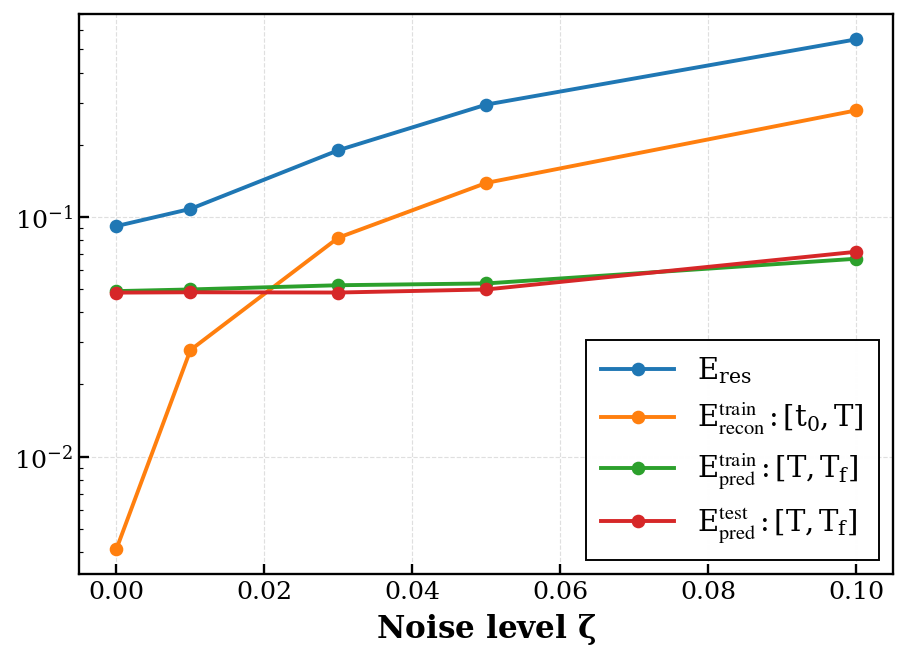

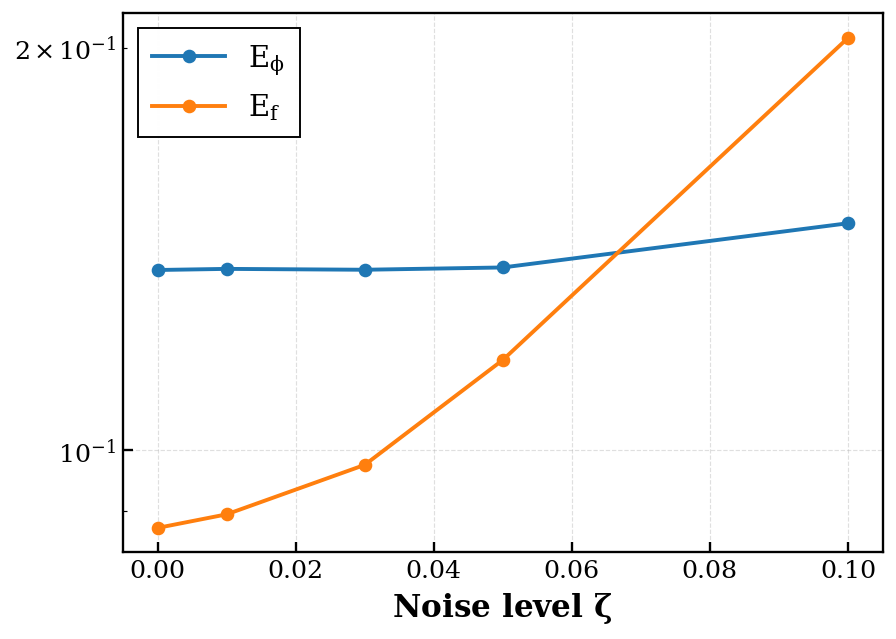

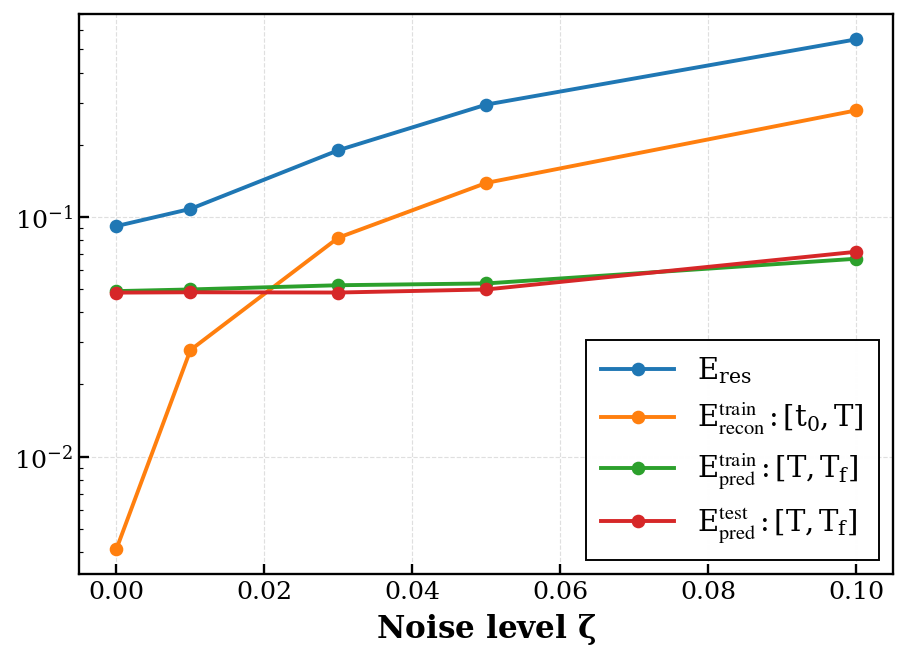

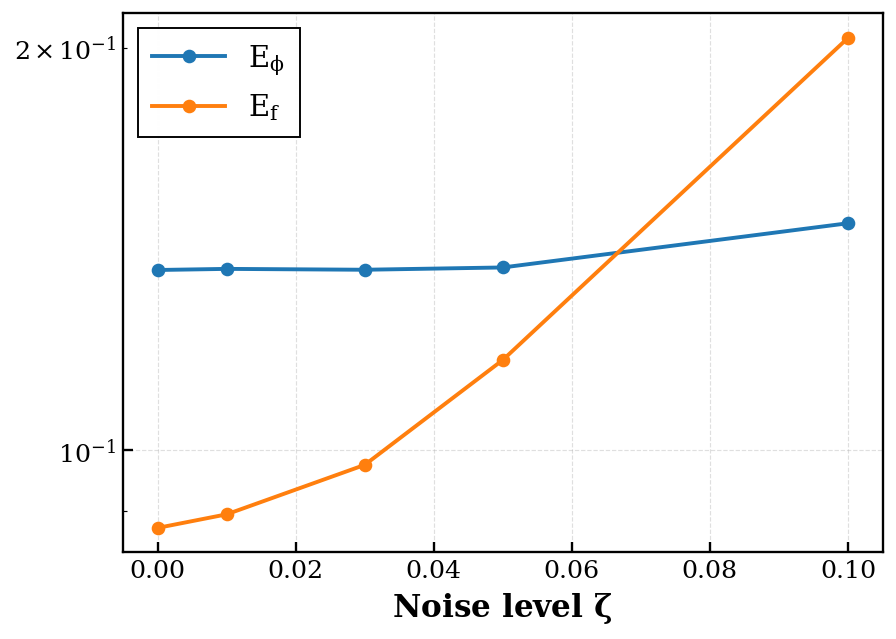

In [36]:
from ips_learning.visualization.noise_sweep import NoiseSweepVisualizer

viz = NoiseSweepVisualizer(
    system_name=SYSTEM_NAME,
    artifact_root=ARTIFACTS,
    stage_name="step_6D",
)

df_noise = viz.load_metrics(
    noise_metrics_path
)

viz.generate_all(noise_metrics_path)

## Noice vs features

In [37]:
import numpy as np

from ips_learning.fitting.system_repository import NormalSystemRepository
from ips_learning.bases.repository import BasisRepository
from ips_learning.models.factories import LearnedModelFactory
from ips_learning.systems.registry import (
    true_kernel_from_metadata,
    true_env_from_metadata,
)
from ips_learning.data.dataset_repository import DatasetRepository
from ips_learning.visualization.noise_sweep import NoiseSweepVisualizer

In [38]:
def noise_case_name(noise_level: float) -> str:
    noise_tag = f"noise_{str(noise_level).replace('.', 'p')}"
    return f"trial_000_{noise_tag}"


def load_noise_learned_model(noise_level: float, N: int, D: int):
    case_name = noise_case_name(noise_level)

    fit_repo = NormalSystemRepository(root_dir=ARTIFACTS / "fits")

    fit_result = fit_repo.load_fit_result(
        system_name=SYSTEM_NAME,
        profile_name=PROFILE_NAME,
        fit_case_name=case_name,
    )

    return LearnedModelFactory().build_from_fit_result(
        fit_result=fit_result,
        N=N,
        D=D,
    )

In [39]:
dataset_repo = DatasetRepository(root_dir=ARTIFACTS / "datasets")

train_fit_clean = dataset_repo.load(
    system_name=SYSTEM_NAME,
    split=TRAIN_FIT_SPLIT,
    dataset_name=TRAIN_FIT_DATASET_NAME,
)

N = int(train_fit_clean.metadata["N"])
D = int(train_fit_clean.metadata["D"])
SYSTEM_ORDER = int(train_fit_clean.metadata.get("system_order", SYSTEM_ORDER))

ENVIRONMENT_VARIABLE = "position" if SYSTEM_ORDER == 1 else "velocity"

true_phi = true_kernel_from_metadata(train_fit_clean.metadata)
true_f = true_env_from_metadata(train_fit_clean.metadata)

learned_models = {
    float(zeta): load_noise_learned_model(float(zeta), N=N, D=D)
    for zeta in df_noise["noise_level"].to_numpy()
}

In [40]:
basis_repo = BasisRepository(root_dir=ARTIFACTS / "bases")

reference_noise_level = float(df_noise["noise_level"].min())
reference_case_name = noise_case_name(reference_noise_level)

basis_bundle = basis_repo.load(
    system_name=SYSTEM_NAME,
    split="noise_sweep",
    basis_name=reference_case_name,
)

In [ ]:
# Reuse the empirical training density already built above.
pdf_r_ref = train_density
pdf_z_ref = train_density_grid


In [ ]:
# Use the same canonical empirical-density grids for noise visualizations.
r_grid = empirical_density.r_grid
z1_grid = empirical_density.z1_grid
z2_grid = empirical_density.z2_grid


Saved: ./artifacts/spp/figures/step_6D/noise_sweep_phi_by_noise.png
Saved: ./artifacts/spp/figures/step_6D/noise_sweep_env_surfaces_by_noise.png


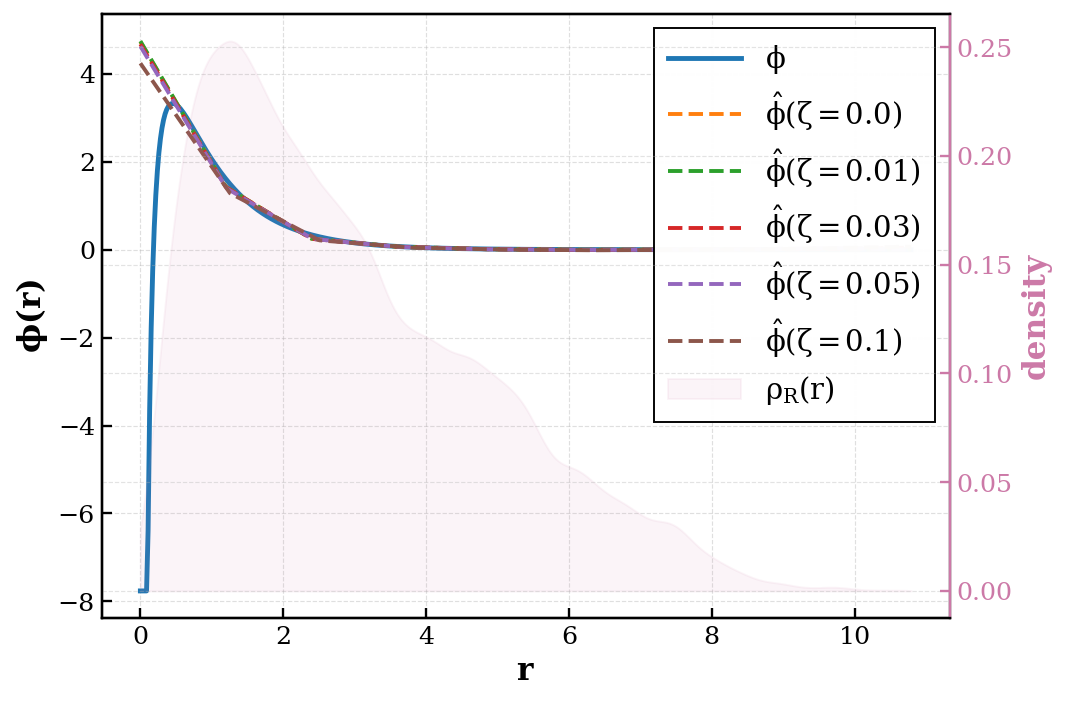

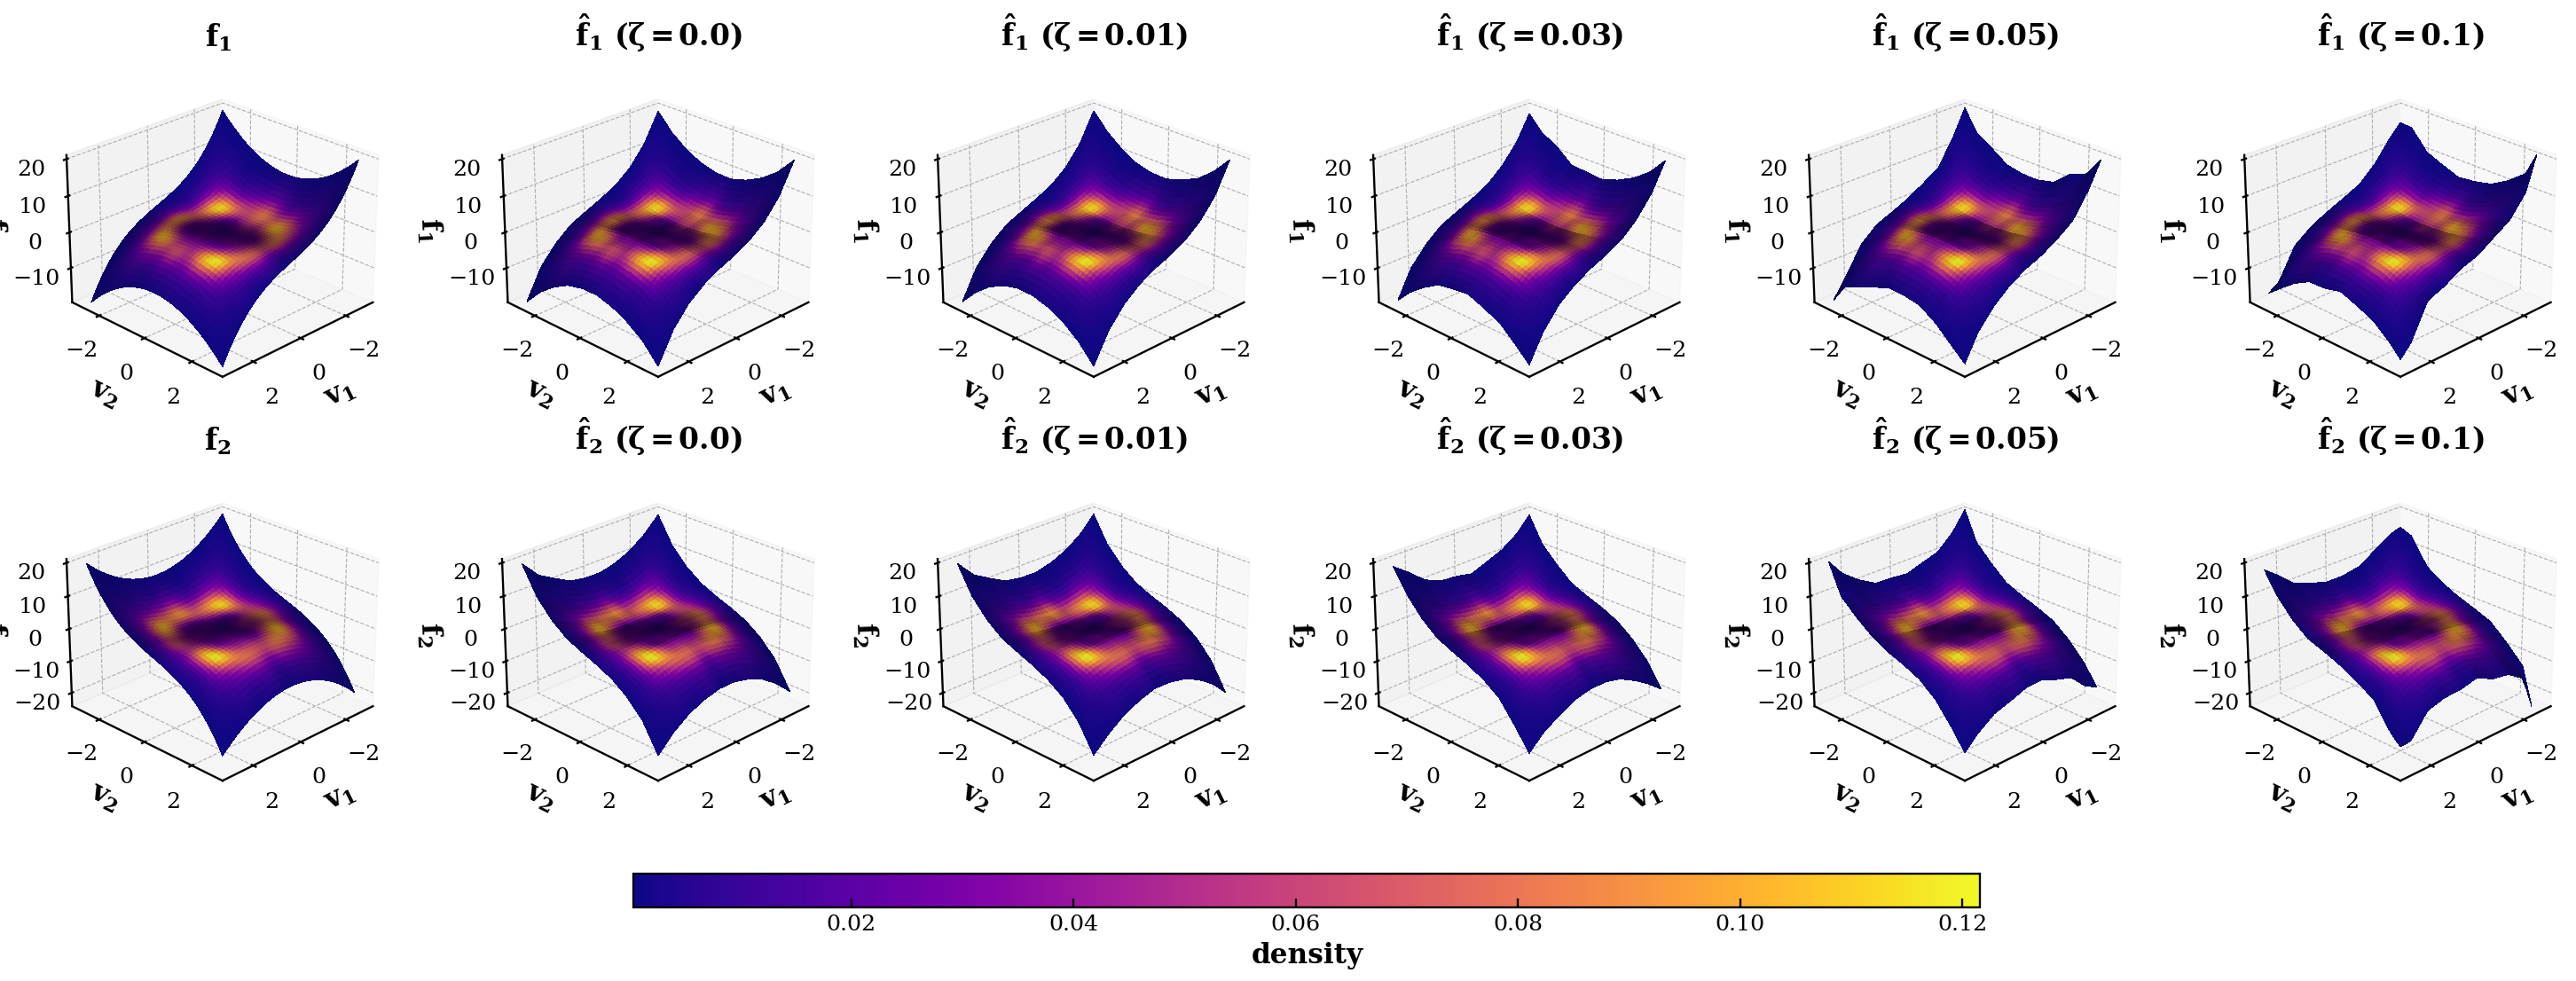

In [43]:
path_phi = viz.plot_phi_vs_r_noise_panel(
    r_grid=r_grid,
    true_phi=true_phi,
    learned_phi_by_noise={
        zeta: model.learned_kernel
        for zeta, model in learned_models.items()
    },
    dist_density_ref=pdf_r_ref,
    figure_name="noise_sweep_phi_by_noise",
    labels={
        "xlabel": r"$r$",
        "ylabel_left": r"$\phi(r)$",
        "density": r"$\rho_R(r)$",
         "ylabel_right": "density",
    },
)

print("Saved:", path_phi)
if D == 1:
    path_env = viz.plot_env_curves_by_noise(
        z_grid=z1_grid,
        true_env=true_f,
        learned_env_by_noise={
            zeta: model.learned_environment
            for zeta, model in learned_models.items()
        },
        env_density_ref=pdf_z_ref,
        figure_name="noise_sweep_env_curves_by_noise",
        labels={
            "xlabel": r"$x$",
            "ylabel_left": r"$f(x)$",
             "density": "density",
        },
    )

elif D == 2:
    if z2_grid is None:
        raise ValueError("z2_grid is required for 2D environment surface plots.")

    path_env = viz.plot_env_surfaces_by_noise(
        v1_grid=z1_grid,
        v2_grid=z2_grid,
        true_env=true_f,
        learned_env_by_noise={
            zeta: model.learned_environment
            for zeta, model in learned_models.items()
        },
        vel_density_ref=pdf_z_ref,
        figure_name="noise_sweep_env_surfaces_by_noise",
        labels={
            "xlabel": r"$v_1$",
            "ylabel": r"$v_2$",
             "density_colorbar": "density",
        }
    )

else:
    raise NotImplementedError(f"Noise-sweep environment visualization supports D=1 or D=2, got D={D}.")

print("Saved:", path_env)

# remove the y label for interaction kernel

## noise vs trajectory phase portraits

In [44]:
from ips_learning.rollout.repository import RolloutRepository
from ips_learning.data.dataset_repository import DatasetRepository
from ips_learning.data.noise import AdditiveGaussianNoise

rollout_repo = RolloutRepository(root_dir=ARTIFACTS / "rollouts")
dataset_repo = DatasetRepository(root_dir=ARTIFACTS / "datasets")

In [45]:
train_fit_clean = dataset_repo.load(
    system_name=SYSTEM_NAME,
    split=TRAIN_FIT_SPLIT,
    dataset_name=TRAIN_FIT_DATASET_NAME,
)

train_full_clean = dataset_repo.load(
    system_name=SYSTEM_NAME,
    split=TRAIN_SPLIT,
    dataset_name=TRAIN_DATASET_NAME,
)

D = train_full_clean.X.shape[-1]

In [46]:
def noise_case_name(noise_level: float) -> str:
    noise_tag = f"noise_{str(noise_level).replace('.', 'p')}"
    return f"trial_000_{noise_tag}"

Saved: ./artifacts/spp/figures/step_6D/noise_sweep_seen_ic_phase_noise_0p0.png
Saved: ./artifacts/spp/figures/step_6D/noise_sweep_seen_ic_phase_noise_0p01.png
Saved: ./artifacts/spp/figures/step_6D/noise_sweep_seen_ic_phase_noise_0p03.png
Saved: ./artifacts/spp/figures/step_6D/noise_sweep_seen_ic_phase_noise_0p05.png
Saved: ./artifacts/spp/figures/step_6D/noise_sweep_seen_ic_phase_noise_0p1.png


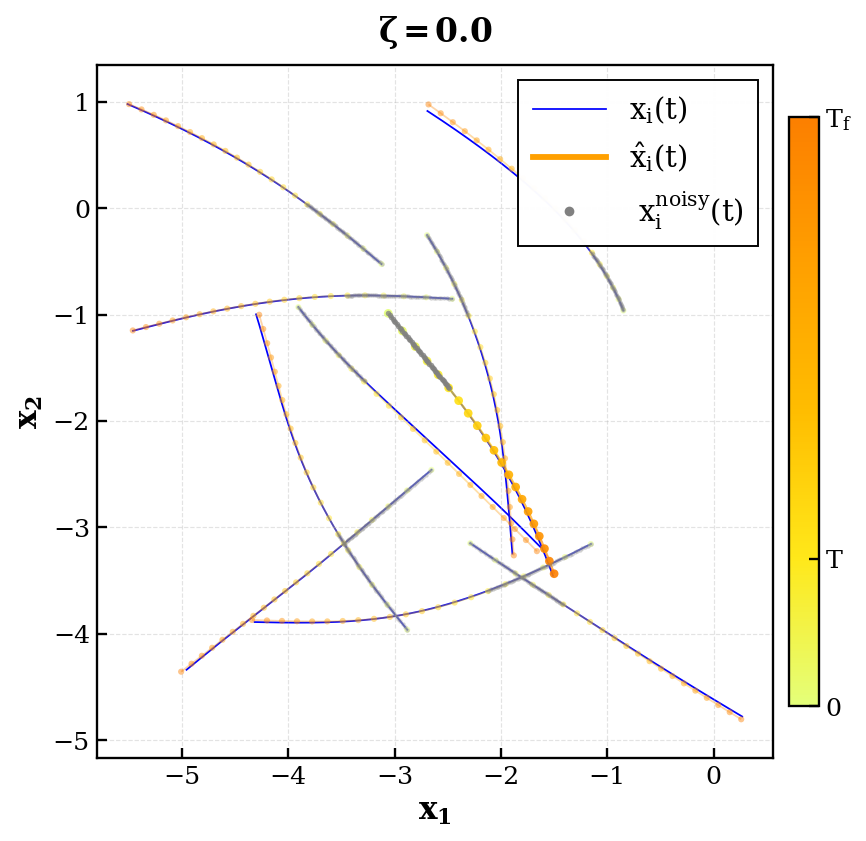

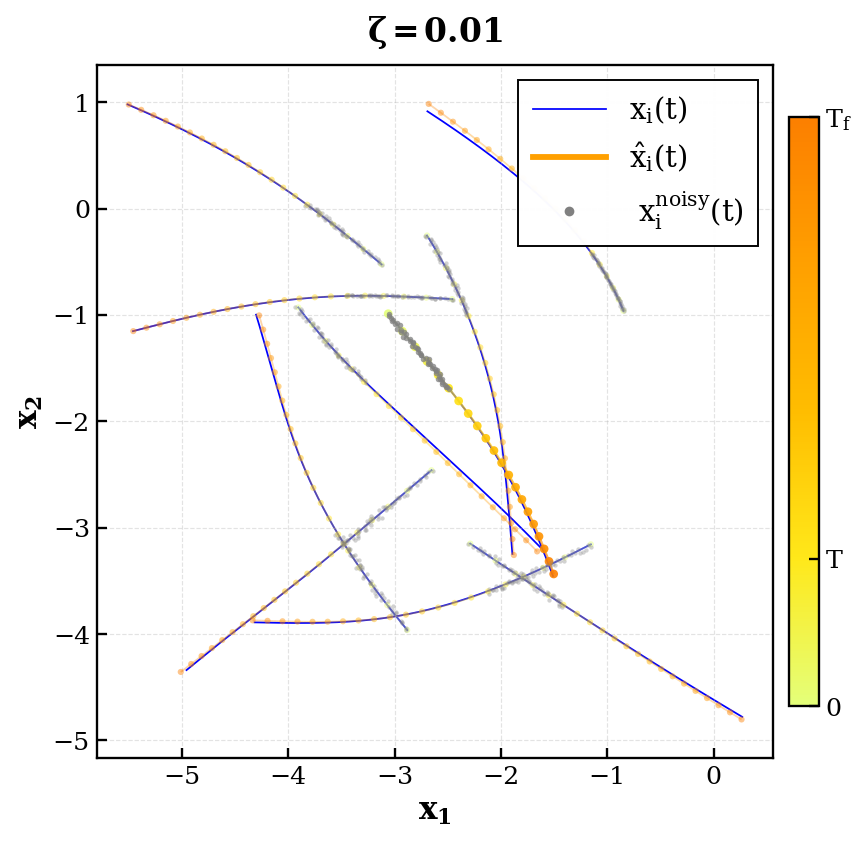

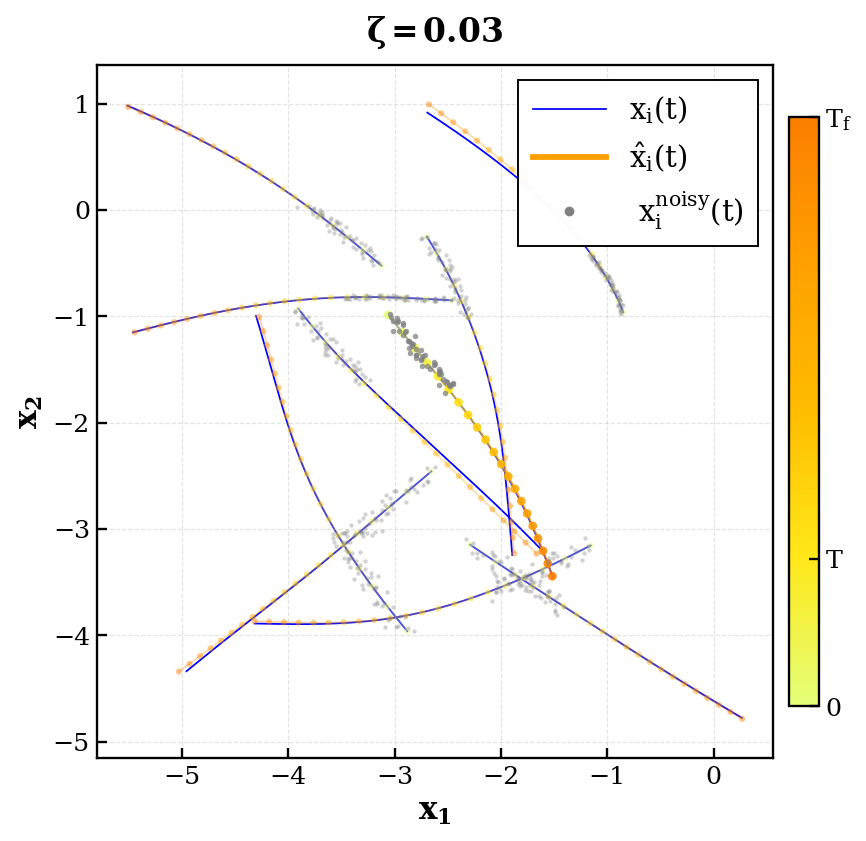

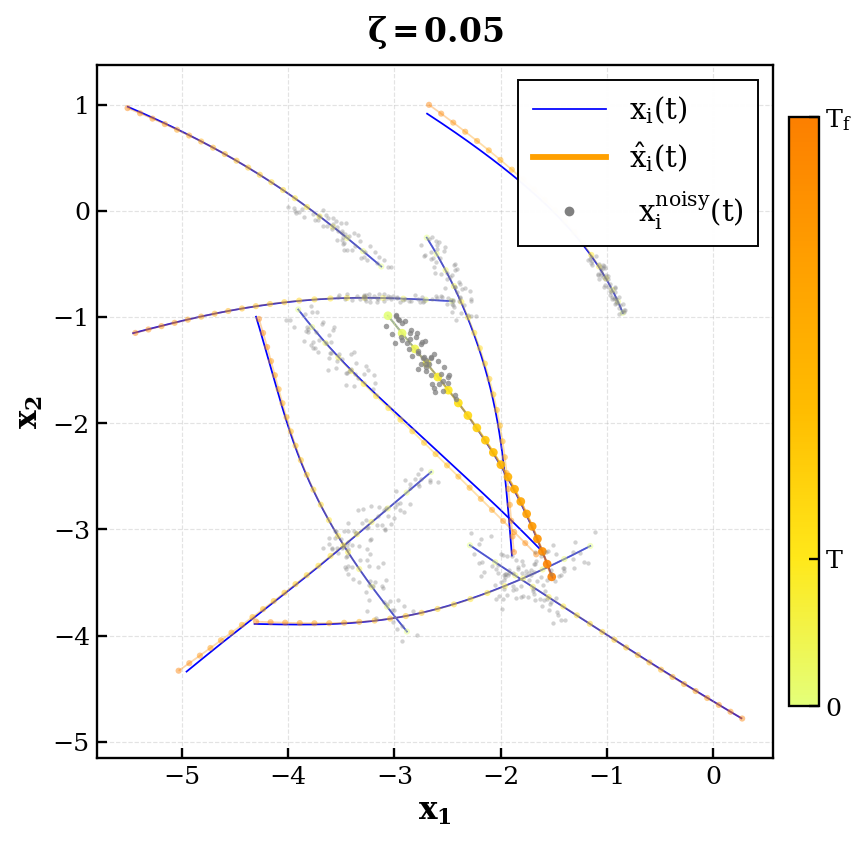

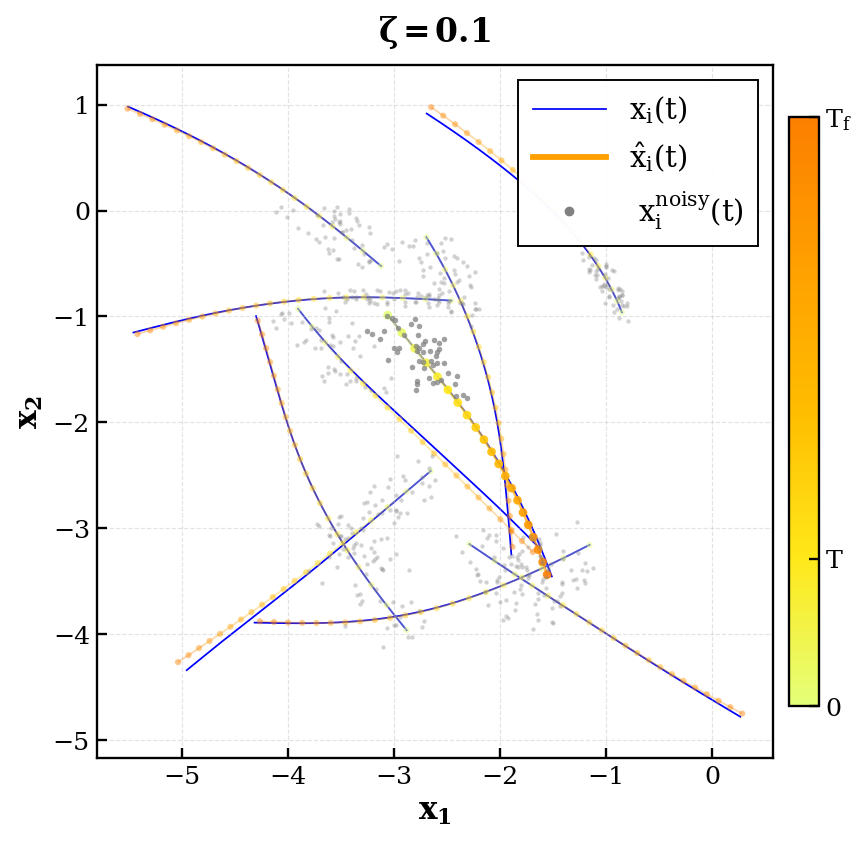

In [47]:
m = 0

for noise_level in NOISE_LEVELS:
    case_name = noise_case_name(noise_level)

    noise_model = AdditiveGaussianNoise(
        noise_level=noise_level,
        seed=NOISE_SEED_BASE + int(noise_level * 1000),
        noise_type=NOISE_TYPE,
    )

    train_fit_noisy = noise_model.perturb(train_fit_clean)

    train_pred_artifact = rollout_repo.load_case(
        system_name=SYSTEM_NAME,
        profile_name=PROFILE_NAME,
        case_name=case_name,
        scenario="noise_same_ic_prediction",
        rollout_name=f"{case_name}_noise_same_ic_prediction",
    )

    X_true_full = train_full_clean.X[m].transpose(1, 2, 0)
    X_learned_full = train_pred_artifact.X_hat[m].transpose(1, 2, 0)
    X_noisy_fit = train_fit_noisy.X[m].transpose(1, 2, 0)

    noise_tag = str(noise_level).replace(".", "p")

    if D == 1:
        path = viz.plot_seen_ic_coordinate_by_noise(
            t_full=train_full_clean.t,
            X_true_full=X_true_full,
            X_learned_full=X_learned_full,
            t_noisy=train_fit_clean.t,
            X_noisy_fit=X_noisy_fit,
            noise_level=noise_level,
            T=FIT_END_TIME,
            Tf=train_full_clean.t[-1],
            ic_index=m,
            component=0,
            figure_name=f"noise_sweep_seen_ic_coordinate_noise_{noise_tag}",
            labels={
                "xlabel": r"$t$",
                "ylabel": r"$x_i(t)$",
                "true": r"$x_i(t)$",
                "learned": r"$\hat{x}_i(t)$",
                "noisy": r"$x_i^{noisy}(t)$",
            },
        )

    elif D == 2:
        path = viz.plot_seen_ic_phase_portrait_by_noise(
            t_full=train_full_clean.t,
            X_true_full=X_true_full,
            X_learned_full=X_learned_full,
            t_noisy=train_fit_clean.t,
            X_noisy_fit=X_noisy_fit,
            noise_level=noise_level,
            T=FIT_END_TIME,
            Tf=train_full_clean.t[-1],
            ic_index=m,
            figure_name=f"noise_sweep_seen_ic_phase_noise_{noise_tag}",
        )

    else:
        raise NotImplementedError(f"Noise trajectory visualization supports D=1 or D=2, got D={D}.")

    print("Saved:", path)